# Food Classes Classification Using CNN
# By: Suchitra Thanumalayan

- **Part 1:** Data Analysis report: what the food images look like (size, quality, colour) and what makes the classes easy or hard to separate
- **Part 2:** Predictive Model: a **Convolutional Neural Network (CNN)** that looks at a photo and says **which of the 101 types of food** it shows
- **Part 3:** Suggestions on how to use the model in a real food app
- **Part 4:** Model Comparison Report

## Project Goal
Create a model that can **classify the type of food** in a photo.

## Data Source
The data is the folder **`food-101.zip`** (5.1 GB). It contains **101 folders, one per food type** (apple_pie, bibimbap, sushi, waffles, ...), each with about 1,000 colour photos in JPG format. These are real photos taken by people (from the website foodspotting.com), so they come with different light, angles, plates, backgrounds and some wrong labels. The zip has **only the images**, with no ready-made train / test split, so we make our own split in Part 2.

The zip was extracted into the folder `food_data/`.

## Tools
- **PyTorch + torchvision** to build and train the CNNs. The laptop has an **Intel Arc 140V GPU**, which PyTorch uses as device `xpu`.
- pandas, matplotlib, seaborn and scikit-learn for the analysis, the tables and the metrics.

In [1]:
import os, io, time, hashlib, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

DATA_DIR = 'food_data'       # extracted food-101.zip
CACHE_DIR = 'food_cache'     # resized images and image details (made once)
MODEL_DIR = 'food_models'    # trained models and their training history
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = 'xpu' if torch.xpu.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch', torch.__version__, '| device:', device, '|', torch.xpu.get_device_name(0) if device == 'xpu' else '')

PyTorch 2.8.0+xpu | device: xpu | Intel(R) Arc(TM) 140V GPU (16GB)


In [2]:
# one row per image: food class, file name and path
classes = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
rows = []
for c in classes:
    for f in sorted(os.listdir(os.path.join(DATA_DIR, c))):
        rows.append((c, f, os.path.join(DATA_DIR, c, f)))
df = pd.DataFrame(rows, columns=['Class', 'File', 'Path'])
print('Number of food classes:', len(classes))
df.head()

Number of food classes: 101


,Class,File,Path
0,apple_pie,1005649.jpg,food_data\apple_pie\1005649.jpg
1,apple_pie,1011328.jpg,food_data\apple_pie\1011328.jpg
2,apple_pie,101251.jpg,food_data\apple_pie\101251.jpg
3,apple_pie,1014775.jpg,food_data\apple_pie\1014775.jpg
4,apple_pie,1026328.jpg,food_data\apple_pie\1026328.jpg


# Part 1: Data Analysis Report
## 1. Basic Checks

In [3]:
df.shape

(101000, 3)

In [4]:
df['Class'].value_counts().describe()

count     101.0
mean     1000.0
std         0.0
min      1000.0
25%      1000.0
50%      1000.0
75%      1000.0
max      1000.0
Name: count, dtype: float64

In [5]:
df['File'].str.split('.').str[-1].value_counts()

File
jpg    101000
Name: count, dtype: int64

In [6]:
# read every file once: image width, height, colour mode, format, file size and a fingerprint (MD5)
# the MD5 is the same for two files only if they are exactly the same image -> finds duplicates
def image_info(path):
    with open(path, 'rb') as fh:
        data = fh.read()
    try:
        im = Image.open(io.BytesIO(data))
        w, h, mode, fmt = im.size[0], im.size[1], im.mode, im.format
    except Exception:
        w, h, mode, fmt = np.nan, np.nan, 'ERROR', 'ERROR'
    return w, h, mode, fmt, len(data) / 1024, hashlib.md5(data).hexdigest()

INFO_FILE = os.path.join(CACHE_DIR, 'image_info.csv')
if os.path.exists(INFO_FILE):
    info = pd.read_csv(INFO_FILE)
else:
    with ThreadPoolExecutor(8) as ex:
        info = pd.DataFrame(list(ex.map(image_info, df['Path'])),
                            columns=['Width', 'Height', 'Mode', 'Format', 'File KB', 'MD5'])
    info.to_csv(INFO_FILE, index=False)
df = pd.concat([df, info], axis=1)
df.head()

,Class,File,Path,Width,Height,Mode,Format,File KB,MD5
0,apple_pie,1005649.jpg,food_data\apple_pie\1005649.jpg,308,512,RGB,JPEG,41.207031,6315170b5af2b73805423748af281b99
1,apple_pie,1011328.jpg,food_data\apple_pie\1011328.jpg,512,512,RGB,JPEG,39.804688,812eba7c434de9b40348454ea6a579bf
2,apple_pie,101251.jpg,food_data\apple_pie\101251.jpg,384,512,RGB,JPEG,33.041992,d87808971f57c13ba3ee7940bd2a25d5
3,apple_pie,1014775.jpg,food_data\apple_pie\1014775.jpg,512,512,RGB,JPEG,46.924805,db19a3f4f801cf7be158a44b9d01e3ad
4,apple_pie,1026328.jpg,food_data\apple_pie\1026328.jpg,512,512,RGB,JPEG,57.670898,3819703a413e9ad54f9bea7cdacdee5f


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101000 entries, 0 to 100999
Data columns (total 9 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   Class    101000 non-null  str    
 1   File     101000 non-null  str    
 2   Path     101000 non-null  str    
 3   Width    101000 non-null  int64  
 4   Height   101000 non-null  int64  
 5   Mode     101000 non-null  str    
 6   Format   101000 non-null  str    
 7   File KB  101000 non-null  float64
 8   MD5      101000 non-null  str    
dtypes: float64(1), int64(2), str(6)
memory usage: 15.9 MB


In [8]:
df.describe()

,Width,Height,File KB
count,101000.000000,101000.000000,101000.000000
mean,495.791396,475.372129,49.472288
std,45.674348,65.305769,14.470559
min,193.000000,122.000000,8.489258
25%,512.000000,452.000000,39.786133
50%,512.000000,512.000000,48.423340
75%,512.000000,512.000000,57.134766
max,512.000000,512.000000,210.645508


In [9]:
df.isnull().sum()

Class      0
File       0
Path       0
Width      0
Height     0
Mode       0
Format     0
File KB    0
MD5        0
dtype: int64

In [10]:
df['Mode'].value_counts()

Mode
RGB    100997
L           3
Name: count, dtype: int64

In [11]:
df['Format'].value_counts()

Format
JPEG    101000
Name: count, dtype: int64

In [12]:
# exact duplicate images (same MD5)
dup = df[df.duplicated('MD5', keep=False)]
dup_class_count = dup.groupby('MD5')['Class'].nunique()
print('Images that appear more than once:', len(dup))
print('Extra copies (duplicates to remove):', df.duplicated('MD5').sum())
print('Duplicate groups inside the same class:', (dup_class_count == 1).sum())
print('Duplicate groups across DIFFERENT classes:', (dup_class_count > 1).sum())
dup.sort_values('MD5')[['Class', 'File', 'Width', 'Height', 'File KB']].head(10)

Images that appear more than once: 16
Extra copies (duplicates to remove): 8
Duplicate groups inside the same class: 6
Duplicate groups across DIFFERENT classes: 2


,Class,File,Width,Height,File KB
23448,churros,2547960.jpg,512,512,47.748047
23475,churros,2617186.jpg,512,512,47.748047
67448,omelette,2619753.jpg,512,512,54.776367
72418,pancakes,2619752.jpg,512,512,54.776367
75827,pho,51122.jpg,512,384,75.809570
75883,pho,651427.jpg,512,384,75.809570
75808,pho,4787.jpg,384,512,61.498047
75826,pho,51112.jpg,384,512,61.498047
32216,dumplings,167000.jpg,512,384,77.753906
32250,dumplings,180290.jpg,512,384,77.753906


In [13]:
# how many images are smaller than 512 pixels on their longest side?
df['LONG SIDE'] = df[['Width', 'Height']].max(axis=1)
print('Longest side = 512 px:', (df['LONG SIDE'] == 512).sum(), '| smaller than 512 px:', (df['LONG SIDE'] < 512).sum())
print('Square images (512 x 512):', ((df['Width'] == 512) & (df['Height'] == 512)).sum())
print('Smallest images (min side < 200 px):', (df[['Width', 'Height']].min(axis=1) < 200).sum())

Longest side = 512 px: 101000 | smaller than 512 px: 0
Square images (512 x 512): 62206


Smallest images (min side < 200 px): 7


**Observations**
- The data has **101,000 images in 101 food classes**, exactly **1,000 images per class**, so the classes are perfectly **balanced** (no class gets more attention from the model just because it has more photos).
- All files are **JPG**, there are **no missing values** and **no broken files** (every image could be opened).
- **3 images are grayscale** (mode `L`, one each in bread_pudding, lasagna and steak). All others are RGB colour images.
- **Every image has 512 pixels on its longest side** (the dataset was already resized by its authors). **62,206 images (61.6%) are square 512 x 512**, the rest are portrait or landscape, down to 512 x 122 for the narrowest one. 7 images have a short side below 200 px.
- File size goes from **8.5 KB to 210.6 KB** (average 49.5 KB).
- **Duplicates:** 8 extra copies were found (same MD5 fingerprint). 6 are the same photo saved twice in the same class (e.g. two identical churros photos, three pairs in pho/dumplings). **2 groups are the same photo in two different classes** (e.g. one photo is both in `omelette` and `pancakes`), which means a **wrong label**.

## 2. Cleaning and Preparing the Images
A CNN needs every image to have the **same size**, and reading 5 GB of JPG files again in every training round would be very slow. So the images are prepared **once**:
1. **Duplicates removed:** an exact copy inside the same class is dropped (kept once). If the same image is in two *different* classes, all copies are dropped because we cannot know the right label.
2. **Grayscale / CMYK images converted to RGB** (3 colour channels), so every image has the same shape.
3. **Resized** so the short side is 240 pixels, then the **centre 240 x 240** square is cut out. During training a random crop of this square is used (the model sees slightly different pieces each time), and for testing the centre 224 x 224 is used. 224 x 224 is the size the pretrained CNNs were built for.
4. All images are stored in one big array file (`food_cache/images_240.npy`, about 17 GB) that can be read very quickly.

New columns (UPPERCASE) are added for the analysis: **ASPECT RATIO** (width / height), **MEAN RED / GREEN / BLUE** (average colour), **BRIGHTNESS** (average gray level, 0 = black, 255 = white) and **CONTRAST** (spread of the gray levels).

In [14]:
before = len(df)
cross_class = dup_class_count[dup_class_count > 1].index
df = df[~df['MD5'].isin(cross_class)]           # same image in different classes -> drop all copies
df = df.drop_duplicates('MD5', keep='first')     # same image twice in one class -> keep one
df = df.reset_index(drop=True)
print('Images before:', before, '| after removing duplicates:', len(df), '| removed:', before - len(df))
df['ASPECT RATIO'] = (df['Width'] / df['Height']).round(3)

Images before: 101000 | after removing duplicates: 100990 | removed: 10


In [15]:
CACHE_SIZE = 240

def load_and_resize(path):
    im = Image.open(path)
    im.draft('RGB', (CACHE_SIZE, CACHE_SIZE))   # fast JPG decoding at a smaller size (never below 240 px)
    im = im.convert('RGB')
    w, h = im.size
    s = CACHE_SIZE / min(w, h)
    im = im.resize((max(CACHE_SIZE, round(w * s)), max(CACHE_SIZE, round(h * s))), Image.BILINEAR)
    w, h = im.size
    left, top = (w - CACHE_SIZE) // 2, (h - CACHE_SIZE) // 2
    return np.asarray(im.crop((left, top, left + CACHE_SIZE, top + CACHE_SIZE)))

X_FILE = os.path.join(CACHE_DIR, f'images_{CACHE_SIZE}.npy')
KEY_FILE = os.path.join(CACHE_DIR, 'images_order.csv')
if not os.path.exists(X_FILE):
    t0 = time.time()
    X = np.lib.format.open_memmap(X_FILE + '.tmp', mode='w+', dtype=np.uint8,
                                  shape=(len(df), CACHE_SIZE, CACHE_SIZE, 3))
    def work(i):
        X[i] = load_and_resize(df['Path'].iat[i])
    with ThreadPoolExecutor(8) as ex:
        list(ex.map(work, range(len(df))))
    X.flush(); del X
    os.replace(X_FILE + '.tmp', X_FILE)
    df[['Path']].to_csv(KEY_FILE, index=False)
    print(f'Resized {len(df)} images in {(time.time() - t0) / 60:.1f} minutes')
assert (pd.read_csv(KEY_FILE)['Path'].values == df['Path'].values).all()   # same order as df
X = np.load(X_FILE, mmap_mode='r')
X.shape

(100990, 240, 240, 3)

In [16]:
# colour features of every image (calculated on every 4th pixel, which is plenty for an average)
feats = []
for s in range(0, len(df), 2000):
    b = X[s:s + 2000, ::4, ::4].astype(np.float32)
    gray = b.mean(axis=3)
    feats.append(np.c_[b.mean(axis=(1, 2)), gray.mean(axis=(1, 2)), gray.std(axis=(1, 2))])
feats = np.vstack(feats)
df[['MEAN RED', 'MEAN GREEN', 'MEAN BLUE', 'BRIGHTNESS', 'CONTRAST']] = feats.round(1)
df[['Class', 'Width', 'Height', 'File KB', 'ASPECT RATIO', 'MEAN RED', 'MEAN GREEN', 'MEAN BLUE', 'BRIGHTNESS', 'CONTRAST']].describe()

,Width,Height,File KB,ASPECT RATIO,MEAN RED,MEAN GREEN,MEAN BLUE,BRIGHTNESS,CONTRAST
count,100990.000000,100990.000000,100990.000000,100990.000000,100990.000000,100990.000000,100990.000000,100990.000000,100990.000000
mean,495.792841,475.371037,49.470216,1.071668,140.458145,113.513374,86.809509,113.593742,56.916897
std,45.672118,65.306923,14.467312,0.228145,31.460136,28.171276,30.772455,26.461994,13.028115
min,193.000000,122.000000,8.489258,0.377000,1.900000,3.600000,0.900000,2.100000,0.800000
25%,512.000000,452.000000,39.786133,1.000000,119.300003,95.900002,66.400002,96.900002,48.400002
50%,512.000000,512.000000,48.421875,1.000000,140.300003,113.500000,86.900002,113.400002,57.299999
75%,512.000000,512.000000,57.134521,1.133000,162.100006,132.199997,107.300003,131.000000,65.800003
max,512.000000,512.000000,210.645508,4.197000,248.600006,240.000000,224.899994,229.800003,109.599998


**Cleaning result**
- **10 images removed** (6 same-class extra copies + 4 images from the 2 cross-class groups), leaving **100,990 images**. Classes now have 997-1,000 images each, still balanced.
- The 3 grayscale images were converted to RGB.
- All images were resized and centre-cropped to 240 x 240 using 8 threads (a few minutes, done once) and stored in one 17 GB array.
- **Colour:** the average photo is **warm**: red 140.5, green 113.5, blue 86.8 (on a 0-255 scale). Food photos are full of browns, yellows and oranges.
- **Brightness** averages 113.6 but goes from **2.1 (an almost black photo) to 229.8 (almost white)**. **Contrast** averages 56.9.

## 3. Sample Images

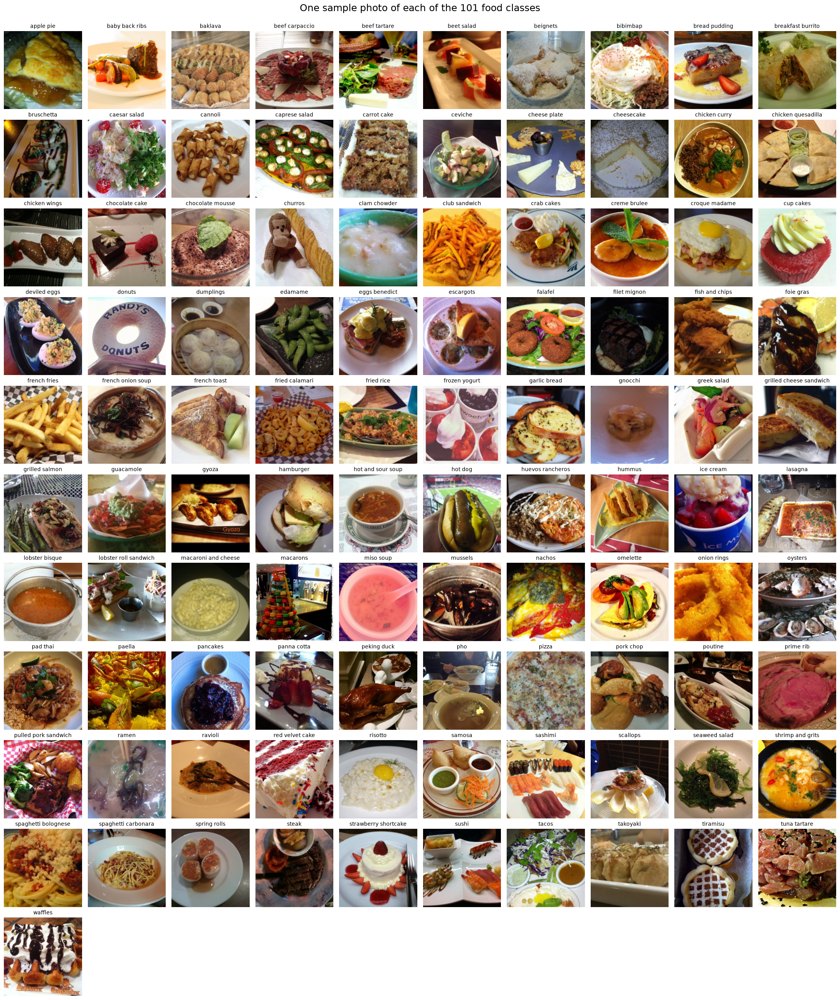

In [17]:
# one random photo of every food class
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(11, 10, figsize=(22, 26))
for ax in axes.ravel():
    ax.axis('off')
for ax, c in zip(axes.ravel(), classes):
    i = rng.choice(np.where(df['Class'] == c)[0])
    ax.imshow(X[i])
    ax.set_title(c.replace('_', ' '), fontsize=10)
plt.suptitle('One sample photo of each of the 101 food classes', fontsize=18, y=1.0)
plt.tight_layout()
plt.show()

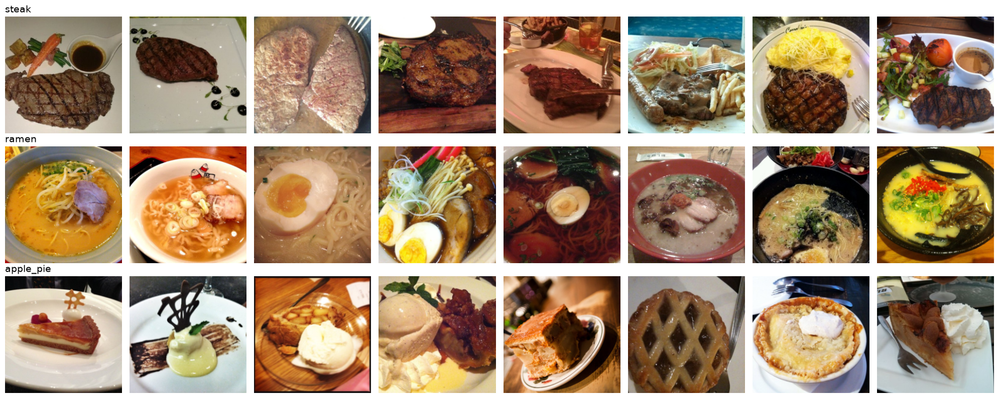

In [18]:
# 8 photos of the same class: how different can one food look?
fig, axes = plt.subplots(3, 8, figsize=(20, 8))
for row, c in zip(axes, ['steak', 'ramen', 'apple_pie']):
    for ax, i in zip(row, rng.choice(np.where(df['Class'] == c)[0], 8, replace=False)):
        ax.imshow(X[i]); ax.axis('off')
    row[0].set_title(c, loc='left', fontsize=14)
plt.tight_layout()
plt.show()

**Insights:**
- The photos are **real-life pictures, not studio photos**: different plates, tables, light, angles and zoom. Many photos show other things too (glasses, menus, side dishes, fries, salads).
- **The same food can look very different.** A steak can be a grilled piece of meat on a white plate or a small part of a plate full of fries and coleslaw. Ramen can have a clear, brown or creamy broth. Many "apple pie" photos show **ice cream, cream and chocolate decorations** more than the pie itself.
- **Different foods can look very similar** (steak vs filet mignon vs prime rib, chocolate cake vs chocolate mousse). This is the main difficulty for the model, and it is why we need a model that learns texture and shape, not just colour.

## 4. Histograms

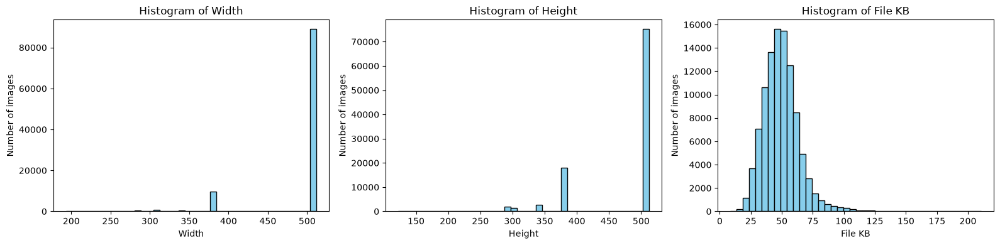

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['Width', 'Height', 'File KB']):
    ax.hist(df[col], bins=40, color='skyblue', edgecolor='black')
    ax.set_title(f'Histogram of {col}')
    ax.set_xlabel(col); ax.set_ylabel('Number of images')
plt.tight_layout()
plt.show()

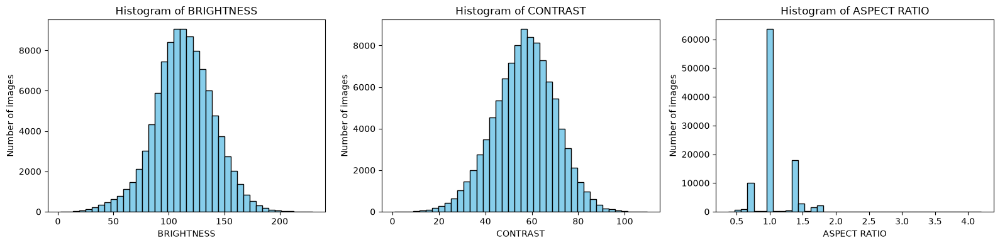

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['BRIGHTNESS', 'CONTRAST', 'ASPECT RATIO']):
    ax.hist(df[col], bins=40, color='skyblue', edgecolor='black')
    ax.set_title(f'Histogram of {col}')
    ax.set_xlabel(col); ax.set_ylabel('Number of images')
plt.tight_layout()
plt.show()

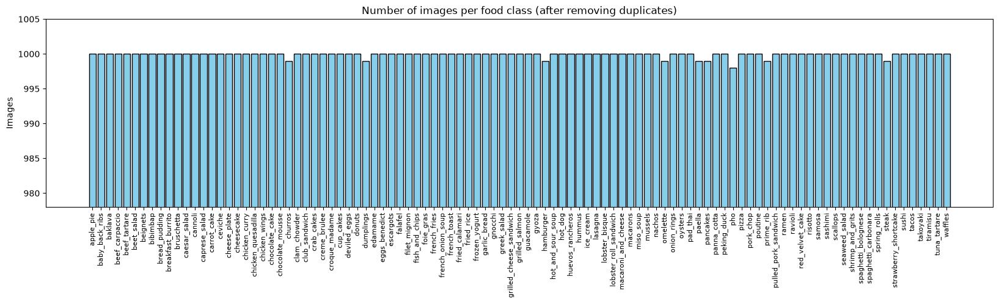

In [21]:
counts = df['Class'].value_counts().sort_index()
plt.figure(figsize=(20, 4))
plt.bar(counts.index, counts.values, color='skyblue', edgecolor='black')
plt.xticks(rotation=90, fontsize=8)
plt.ylim(counts.min() - 20, 1005)
plt.title('Number of images per food class (after removing duplicates)')
plt.ylabel('Images')
plt.show()

**Insights:**
- **Width and Height** have a huge peak at **512**: one side is always 512 px, the other side is 512 (square) or smaller, mostly between about 290 and 512.
- **File size** is bell-shaped around 40-60 KB, with a long right tail up to 210 KB. Large files mean photos with a lot of fine detail (busy plates like paella and pizza).
- **Brightness** is bell-shaped around 110-115, with a few very dark photos (restaurants at night) and some very bright ones (over-exposed white plates). **Contrast** is also bell-shaped around 57.
- **Aspect ratio:** most photos are 1.0 (square, 63,127 photos), with smaller peaks at 1.33 (4:3 landscape, 14,922) and 0.75 (3:4 portrait, 9,651).
- **Images per class:** every class has 997-1,000 images after cleaning, so **no class balancing is needed**.

## 5. Relationship Plots (relplot)

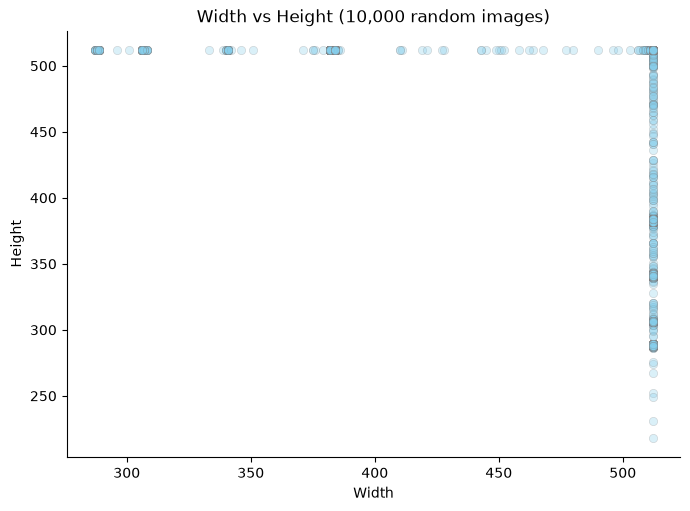

In [22]:
sample = df.sample(10000, random_state=SEED)
sns.relplot(data=sample, x='Width', y='Height', alpha=0.3, color='skyblue', edgecolor='gray', height=5, aspect=1.4)
plt.title('Width vs Height (10,000 random images)')
plt.show()

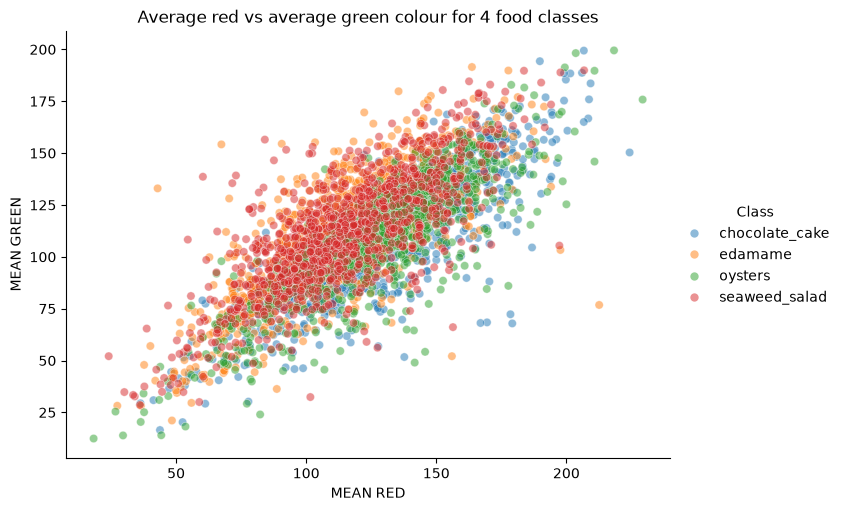

In [23]:
four = ['chocolate_cake', 'edamame', 'seaweed_salad', 'oysters']
sub = df[df['Class'].isin(four)]
sns.relplot(data=sub, x='MEAN RED', y='MEAN GREEN', hue='Class', alpha=0.5, height=5, aspect=1.4)
plt.title('Average red vs average green colour for 4 food classes')
plt.show()

**Insights:**
- **Width vs Height:** the points lie on two lines only: **height = 512** (landscape and square photos) or **width = 512** (portrait photos). This confirms the photos were resized so the longest side is 512.
- **Red vs Green for 4 classes:** the classes **overlap almost completely**. Edamame and seaweed salad (both green) sit a little lower on red, and chocolate cake and oysters cover nearly the same area. The average colours of these four classes differ by only about 15 points (red 113-129, green 109-112), while photos *inside* one class spread by about 30 points. So **the average colour of a photo says very little about the food**.

## 6. Pair Plot

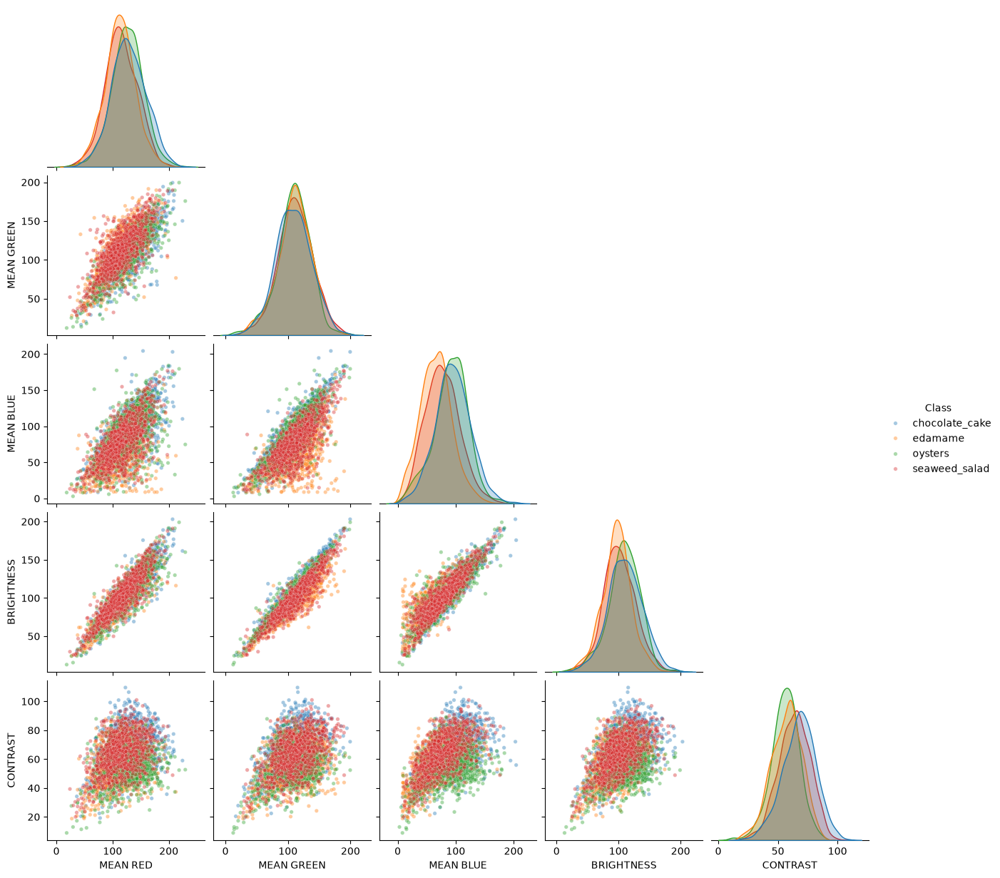

In [24]:
sns.pairplot(sub[['MEAN RED', 'MEAN GREEN', 'MEAN BLUE', 'BRIGHTNESS', 'CONTRAST', 'Class']], hue='Class',
             plot_kws={'alpha': 0.4, 's': 15}, corner=True)
plt.show()

**Insights:**
- **Edamame** is the only class that separates a bit, thanks to its **low blue** (66 on average vs 91-95 for chocolate cake and oysters): green food has less blue.
- **MEAN GREEN and BRIGHTNESS lie almost on a straight line** (correlation 0.96), because green is the biggest part of what our eyes (and the gray formula) see as brightness.
- Apart from that, all the distributions sit on top of each other. Simple colour numbers can't separate these four classes, and this is true for the other 97 classes too. This is the main reason we use a CNN.

## 7. Box Plots and Outliers (IQR method)

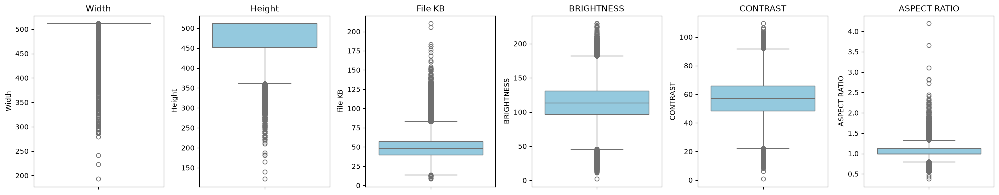

In [25]:
box_cols = ['Width', 'Height', 'File KB', 'BRIGHTNESS', 'CONTRAST', 'ASPECT RATIO']
fig, axes = plt.subplots(1, 6, figsize=(20, 4))
for ax, col in zip(axes, box_cols):
    sns.boxplot(y=df[col], ax=ax, color='skyblue')
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [26]:
outlier_rows = []
for col in box_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    low, high = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    outlier_rows.append([col, round(low, 1), round(high, 1), n_out, round(n_out / len(df) * 100, 2)])
pd.DataFrame(outlier_rows, columns=['Column', 'Lower limit', 'Upper limit', 'Outliers', 'Outliers %'])

,Column,Lower limit,Upper limit,Outliers,Outliers %
0,Width,512.0,512.0,12573,12.45
1,Height,362.0,602.0,6661,6.60
2,File KB,13.8,83.2,2502,2.48
3,BRIGHTNESS,45.8,182.1,1585,1.57
4,CONTRAST,22.3,91.9,813,0.81
5,ASPECT RATIO,0.8,1.3,36217,35.86


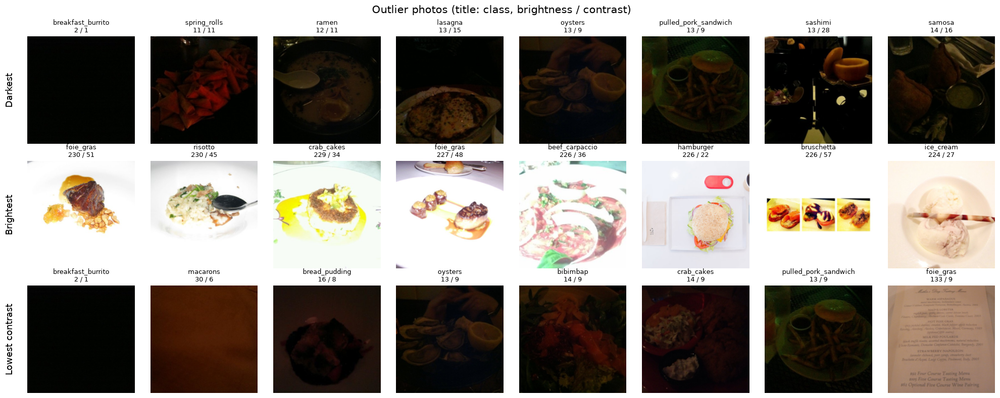

In [27]:
# what do the outliers look like? darkest, brightest and lowest-contrast photos
groups = {'Darkest': df.nsmallest(8, 'BRIGHTNESS').index,
          'Brightest': df.nlargest(8, 'BRIGHTNESS').index,
          'Lowest contrast': df.nsmallest(8, 'CONTRAST').index}
fig, axes = plt.subplots(3, 8, figsize=(20, 8))
for row, (title, idx) in zip(axes, groups.items()):
    for ax, i in zip(row, idx):
        ax.imshow(X[i]); ax.axis('off')
        ax.set_title(f"{df['Class'].iat[i]}\n{df['BRIGHTNESS'].iat[i]:.0f} / {df['CONTRAST'].iat[i]:.0f}", fontsize=9)
    row[0].text(-30, 120, title, rotation=90, va='center', ha='right', fontsize=13)
plt.suptitle('Outlier photos (title: class, brightness / contrast)', fontsize=15)
plt.tight_layout()
plt.show()

**Outliers**
- **Width, Height and Aspect Ratio:** the IQR method marks 12-36% of the images as outliers, but only because 75% of the images are exactly 512 (the IQR is 0). These are **normal portrait / landscape photos, not errors**, so they are kept.
- **File size:** 2,502 outliers (2.5%) above 83 KB: detailed, busy photos. Kept.
- **Brightness:** 1,585 photos (1.6%) are outside 46-182. The darkest photos (top row) were taken in **dark restaurants**: the food is hard to see even for a person. The brightest ones are **over-exposed white plates**, and one bruschetta image is a **collage of three photos**.
- **Contrast:** 813 photos (0.8%), almost the same dark photos.
- **Noise found:** one `breakfast_burrito` image is **completely black** (brightness 2, contrast 1) and one `foie_gras` image is a **photo of the menu**, not food. The dataset's authors say on purpose that the training images contain some noise (wrong or unclear labels).
- **Decision:** the outliers are **kept**. Users of a real food app will also take dark or strange photos, so the model should learn to handle them. Removing a few hundred photos out of 100,990 would not change the training much. We check in Part 3 how much dark photos actually hurt.

## 8. Line Plot: Colour Distribution of the Pixels

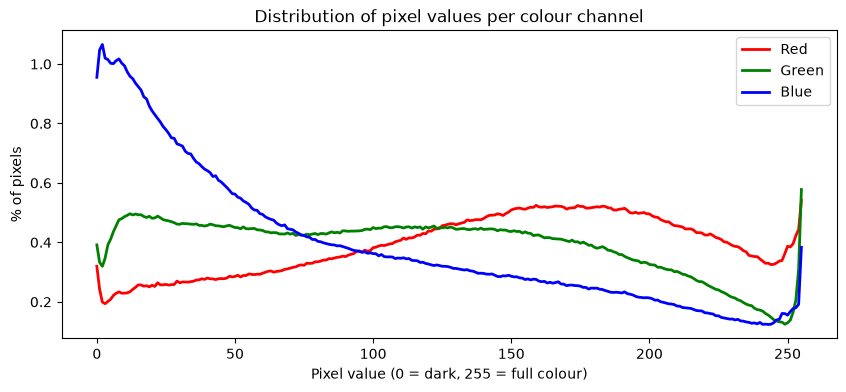

Average value -> red: 140.3, green: 113.7, blue: 87.2


In [28]:
# share of pixels at each intensity (0-255) for each colour channel, from 3,000 random images
pix = X[np.sort(rng.choice(len(df), 3000, replace=False)), ::4, ::4]
plt.figure(figsize=(10, 4))
for ch, (name, colour) in enumerate([('Red', 'red'), ('Green', 'green'), ('Blue', 'blue')]):
    hist = np.bincount(pix[..., ch].ravel(), minlength=256) / pix[..., ch].size * 100
    plt.plot(range(256), hist, color=colour, linewidth=2, label=name)
plt.title('Distribution of pixel values per colour channel')
plt.xlabel('Pixel value (0 = dark, 255 = full colour)'); plt.ylabel('% of pixels')
plt.legend()
plt.show()
print('Average value -> red: %.1f, green: %.1f, blue: %.1f' % tuple(pix.reshape(-1, 3).mean(axis=0)))

**Insights:**
- **Red is the strongest channel** (average 140), then green (114), then blue (87). The red curve is highest between about 150 and 190, the green curve is almost flat, and the **blue curve is highest near 0 and falls steadily**: many pixels have almost no blue. Browns, oranges and yellows (bread, meat, sauces, fried food) are made of red and green with little blue, so food photos are **warm**.
- All three channels have a **small spike at 255**: white plates and over-exposed areas.
- Because the channels have different averages, every channel is **normalised** (mean subtracted, divided by standard deviation) before it goes into the CNN.

## 9. Bar Plots: Which Classes Look Different?

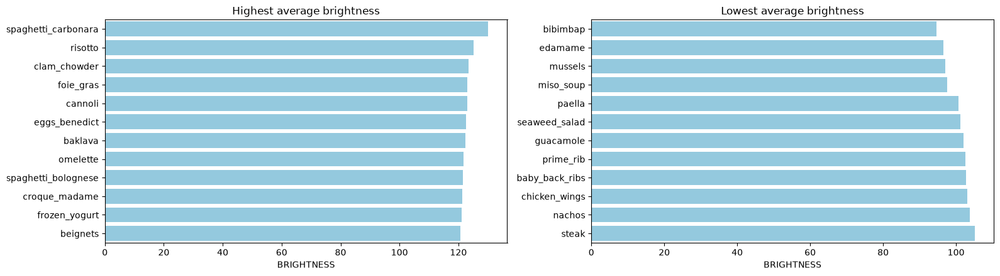

In [29]:
by_class = df.groupby('Class')[['BRIGHTNESS', 'CONTRAST', 'MEAN RED', 'MEAN GREEN', 'MEAN BLUE', 'File KB']].mean()
by_class['GREENNESS'] = by_class['MEAN GREEN'] - (by_class['MEAN RED'] + by_class['MEAN BLUE']) / 2

def class_bars(col, title, n=12):
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
    top = by_class[col].sort_values(ascending=False).head(n)
    bottom = by_class[col].sort_values().head(n)
    sns.barplot(x=top.values, y=top.index, color='skyblue', ax=axes[0])
    sns.barplot(x=bottom.values, y=bottom.index, color='skyblue', ax=axes[1])
    axes[0].set_title(f'Highest {title}'); axes[1].set_title(f'Lowest {title}')
    for ax in axes: ax.set_xlabel(col); ax.set_ylabel('')
    plt.tight_layout()
    plt.show()

class_bars('BRIGHTNESS', 'average brightness')

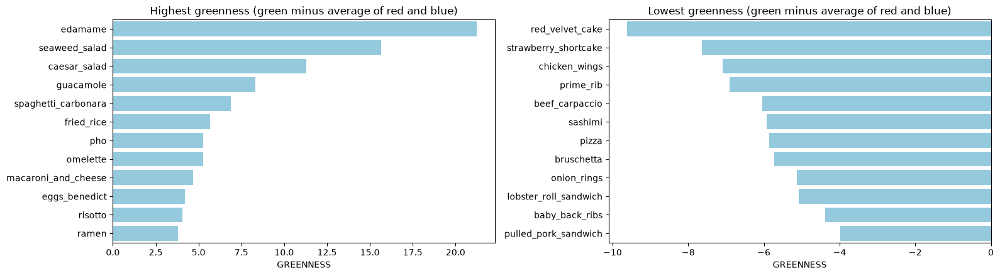

In [30]:
class_bars('GREENNESS', 'greenness (green minus average of red and blue)')

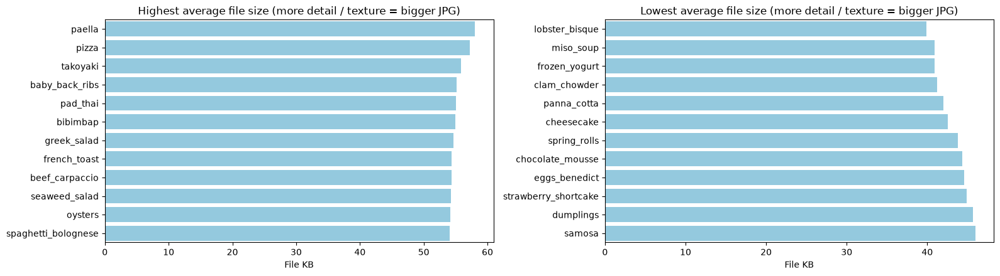

In [31]:
class_bars('File KB', 'average file size (more detail / texture = bigger JPG)')

**Insights:**
- **Brightness:** the brightest classes are creamy, light foods on white plates: **spaghetti carbonara (130.1), risotto (125.2), clam chowder (123.5), cannoli and foie gras (123.0)**. The darkest are **bibimbap (94.6), edamame (96.6), mussels (97.0), miso soup (97.5)**: dark bowls, dark shells and dark sauces. Even so, the difference between the brightest and darkest *class* (35 points) is smaller than the spread inside one class (std 26).
- **Greenness:** only a few classes are really green: **edamame (+21.2), seaweed salad (+15.6), caesar salad (+11.3), guacamole (+8.3)**. The least green are **red velvet cake (-9.6), strawberry shortcake (-7.6), chicken wings (-7.1), prime rib (-6.9)**. These colour-rich classes should be easier for the model.
- **File size:** busy, detailed dishes make bigger JPG files: **paella (58.1 KB), pizza (57.2 KB), takoyaki (55.9 KB)**. Smooth soups and desserts make the smallest: **lobster bisque (39.9 KB), miso soup and frozen yogurt (40.9 KB)**. So texture is a real difference between classes, and texture is exactly what CNN filters learn.

## 10. Label Encoding

In [32]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['LABEL'] = le.fit_transform(df['Class'])
class_names = list(le.classes_)
y_all = df['LABEL'].values
pd.DataFrame({'Class': class_names[:5] + ['...'] + class_names[-3:], 'LABEL': list(range(5)) + ['...'] + list(range(98, 101))}).T

,0,1,2,3,4,5,6,7,8
Class,apple_pie,baby_back_ribs,baklava,beef_carpaccio,beef_tartare,...,tiramisu,tuna_tartare,waffles
LABEL,0,1,2,3,4,...,98,99,100


The 101 food names are turned into numbers **0-100** (alphabetical order), because the model outputs one score for each number.

## 11. Heat Map and Feature Selection

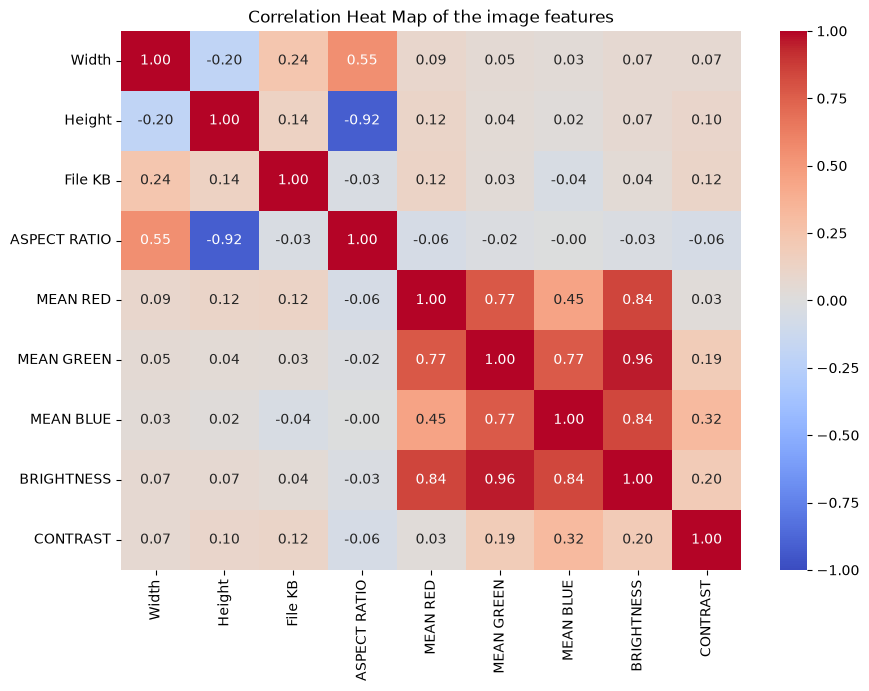

In [33]:
num = df[['Width', 'Height', 'File KB', 'ASPECT RATIO', 'MEAN RED', 'MEAN GREEN', 'MEAN BLUE', 'BRIGHTNESS', 'CONTRAST']]
plt.figure(figsize=(10, 7))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heat Map of the image features')
plt.show()

In [34]:
# how much does each simple feature change between classes? (share of variance explained by the class, eta squared)
eta = {}
for col in num.columns:
    total = ((df[col] - df[col].mean()) ** 2).sum()
    between = (df.groupby('Class')[col].transform('mean') - df[col].mean()).pow(2).sum()
    eta[col] = round(between / total * 100, 1)
pd.Series(eta, name='% of variation explained by the food class').sort_values(ascending=False)

CONTRAST        8.2
MEAN BLUE       8.0
MEAN RED        7.3
BRIGHTNESS      6.3
File KB         6.2
MEAN GREEN      6.2
Width           0.7
Height          0.6
ASPECT RATIO    0.5
Name: % of variation explained by the food class, dtype: float64

**Feature selection**
- **Strong correlations:** BRIGHTNESS is made from the three colours, so it is highly correlated with MEAN GREEN (0.96), MEAN RED (0.84) and MEAN BLUE (0.84). Width and Height are slightly negative (-0.20) because when one side is 512 the other is often smaller. CONTRAST is almost independent of colour (0.03-0.32).
- **Class effect:** the food class explains only **6-8% of the variation** of each colour / contrast / file-size feature, and **less than 1%** of the image size. In other words, **92% or more of the differences between photos have nothing to do with the type of food**.
- **Feature selection for the CNN:** a CNN does not use these hand-made columns. It uses all the **pixels** (224 x 224 x 3 = 150,528 numbers per photo) and learns its own features. The real choices are:
  - **Input size 224 x 224**, the size the pretrained networks were trained with (128 x 128 for the from-scratch CNN to save time).
  - **Keep colour (RGB)**, since some classes (edamame, salads, red velvet cake) are partly recognised by colour.
  - **Normalise** each channel with the ImageNet mean and standard deviation.
- The simple columns are used once more, below, as **Model 0**, to prove that they are not enough.

# Part 2: Predictive Model

## Which algorithm suits this data best?
We want to put each photo into **one of 101 food classes**, so this is a **supervised multi-class image classification** problem.
- A **Convolutional Neural Network (CNN)** reads the raw pixels. Its first layers find edges and colours, the middle layers find textures (noodles, rice grains, crust), and the last layers find whole objects (a burger, a slice of cake). It learns these features by itself, which is why CNNs are the standard model for images.

**Models compared:**
1. **Custom CNN** built from scratch (5 convolution blocks), as a baseline that learns only from our data.
2. **MobileNetV3 as a fixed feature extractor** (transfer learning): a CNN already trained on 1.2 million ImageNet photos turns each food photo into 1,280 numbers, and only a final layer is trained (with a grid search on its settings).
3. **MobileNetV3 fine-tuned**: the whole pretrained network is trained a bit more on food. Small and fast, made for mobile phones.
4. **EfficientNet-B0 fine-tuned**: a modern CNN designed to give high accuracy for little computing power.

Then two ensembles (**soft voting** and **stacking**) and **test-time augmentation**.

**Metrics:** **Accuracy (top-1)** = the first guess is right. **Top-5 accuracy** = the right food is in the 5 best guesses (useful for an app that shows suggestions). **Macro F1** = F1 score averaged over the 101 classes, so every class counts the same.

## Train / Validation / Test Split
Each class is split the same way (stratified): **70% training**, **5% validation** (to watch the training after each round, called an *epoch*), **25% test** (kept apart until the end).

In [35]:
from sklearn.model_selection import train_test_split

idx = np.arange(len(df))
train_idx, test_idx = train_test_split(idx, test_size=0.25, stratify=y_all, random_state=SEED)
train_idx, val_idx = train_test_split(train_idx, test_size=0.0667, stratify=y_all[train_idx], random_state=SEED)
val_idx, test_idx = np.sort(val_idx), np.sort(test_idx)
print('Train:', len(train_idx), '| Validation:', len(val_idx), '| Test:', len(test_idx))

Train: 70690 | Validation: 5052 | Test: 25248


### Model 0: Random Forest on the simple image features (why we need a CNN)

In [36]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score

simple_cols = ['Width', 'Height', 'File KB', 'ASPECT RATIO', 'MEAN RED', 'MEAN GREEN', 'MEAN BLUE', 'BRIGHTNESS', 'CONTRAST']
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=SEED)
rf.fit(df.loc[train_idx, simple_cols], y_all[train_idx])
rf_probs = rf.predict_proba(df.loc[test_idx, simple_cols])

def scores(y_true, probs):
    pred = probs.argmax(1)
    return {'Test Accuracy': accuracy_score(y_true, pred),
            'Top-5 Accuracy': top_k_accuracy_score(y_true, probs, k=5, labels=range(101)),
            'Macro F1': f1_score(y_true, pred, average='macro')}

y_test, y_val = y_all[test_idx], y_all[val_idx]
print({k: round(v, 4) for k, v in scores(y_test, rf_probs).items()})
print('Random guessing would give an accuracy of', round(1 / 101, 4))

{'Test Accuracy': 0.0412, 'Top-5 Accuracy': 0.1353, 'Macro F1': 0.0364}
Random guessing would give an accuracy of 0.0099


**Result:** the Random Forest on the 9 simple features gets only **4.1% accuracy** (top-5: 13.5%). That is 4 times better than random guessing (1.0%), so colour and size carry a little information, but it is far from useful. **We need a model that looks at the shapes and textures inside the photo: a CNN.**

### Data pipeline for the CNNs
- Batches of 64 images are read from the image file by background threads while the GPU is training on the previous batch.
- **Data augmentation (training only):** each image is randomly cropped (35-100% of the area, slightly stretched), resized to 224 x 224, randomly flipped left-right and made a bit brighter or darker. The model never sees exactly the same picture twice, which reduces **overfitting** (memorising the training photos).
- Pixels are **normalised** with the ImageNet mean and standard deviation, as the pretrained networks expect.

In [37]:
IMG_SIZE = 224
BATCH_SIZE = 64
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1) * 255
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1) * 255

def random_resized_crop(img, rng):
    # random area 35-100% and aspect ratio 3/4 - 4/3, then resize to 224 x 224
    for _ in range(10):
        area = CACHE_SIZE * CACHE_SIZE * rng.uniform(0.35, 1.0)
        ratio = np.exp(rng.uniform(np.log(3 / 4), np.log(4 / 3)))
        w, h = int(round(np.sqrt(area * ratio))), int(round(np.sqrt(area / ratio)))
        if w <= CACHE_SIZE and h <= CACHE_SIZE:
            break
    else:
        w = h = CACHE_SIZE
    x0, y0 = rng.integers(0, CACHE_SIZE - w + 1), rng.integers(0, CACHE_SIZE - h + 1)
    out = Image.fromarray(np.ascontiguousarray(img[y0:y0 + h, x0:x0 + w])).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    out = np.asarray(out)
    return out[:, ::-1] if rng.random() < 0.5 else out

def get_batch(b, train, seed):
    b = np.sort(b)                      # reading in file order is faster
    x, y = X[b], y_all[b]
    if train:
        rng = np.random.default_rng(seed)
        x = np.stack([random_resized_crop(img, rng) for img in x])
    else:
        m = (CACHE_SIZE - IMG_SIZE) // 2   # centre crop
        x = x[:, m:m + IMG_SIZE, m:m + IMG_SIZE]
    return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(y.astype(np.int64))

class Loader:
    def __init__(self, ix, batch_size, train):
        self.ix, self.bs, self.train = np.asarray(ix), batch_size, train
    def __len__(self):
        return int(np.ceil(len(self.ix) / self.bs))
    def __iter__(self):
        order = np.random.permutation(self.ix) if self.train else self.ix
        batches = [order[i:i + self.bs] for i in range(0, len(order), self.bs)]
        seeds = np.random.randint(0, 2**31, len(batches))
        with ThreadPoolExecutor(4) as ex:
            futures = [ex.submit(get_batch, batches[i], self.train, seeds[i]) for i in range(min(6, len(batches)))]
            for i in range(len(batches)):
                if i + 6 < len(batches):
                    futures.append(ex.submit(get_batch, batches[i + 6], self.train, seeds[i + 6]))
                yield futures[i].result()
                futures[i] = None

def to_input(xb, size=IMG_SIZE, train=False):
    x = xb.to(device).permute(0, 3, 1, 2).float()
    if train:   # random brightness change of +-20%
        x = (x * torch.empty(len(x), 1, 1, 1, device=device).uniform_(0.8, 1.2)).clamp(0, 255)
    x = ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)
    if size != x.shape[-1]:
        x = F.interpolate(x, size=(size, size), mode='bilinear', antialias=True, align_corners=False)
    return x

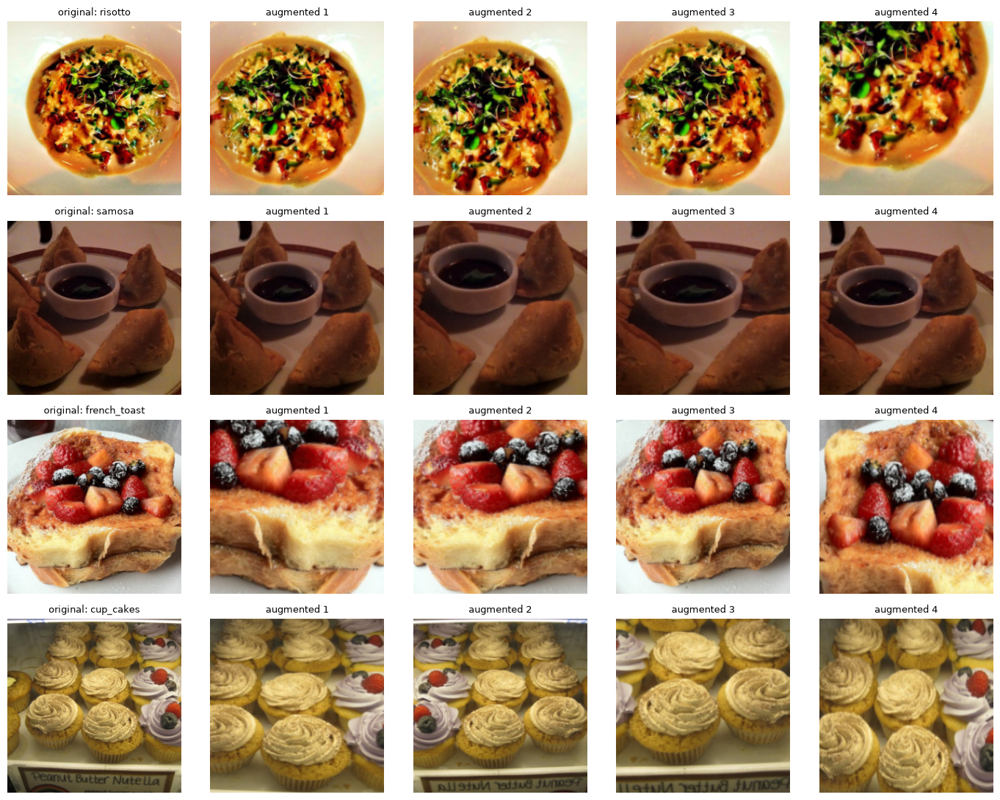

In [38]:
# check: what the model sees after augmentation (same 4 photos, 4 random versions each)
demo = train_idx[:4]
fig, axes = plt.subplots(4, 5, figsize=(14, 11))
for r, i in enumerate(demo):
    axes[r, 0].imshow(X[i]); axes[r, 0].set_title('original: ' + df['Class'].iat[i], fontsize=9)
    for c in range(1, 5):
        axes[r, c].imshow(random_resized_crop(X[i], np.random.default_rng(c * 100 + r)))
        axes[r, c].set_title(f'augmented {c}', fontsize=9)
for ax in axes.ravel(): ax.axis('off')
plt.tight_layout()
plt.show()

### Training and evaluation functions
- **Loss:** cross-entropy with **label smoothing 0.1** (the model is taught to be 90% sure instead of 100% sure, which helps with the wrong labels found in this dataset).
- **Optimizer:** AdamW (Adam with weight decay to keep the weights small).
- **Learning rate:** "one-cycle" schedule: it warms up in the first 15% of training and then slowly goes down to almost zero.
- **Mixed precision (bfloat16)** on the GPU to train faster.
- After every epoch the model is checked on the validation set. The trained model is saved, so the notebook can be run again without training again.

In [39]:
def file_name(name):
    return os.path.join(MODEL_DIR, name.lower().replace(' ', '_').replace('(', '').replace(')', '').replace('-', ''))

speed = {}

@torch.no_grad()
def predict_probs(model, ix, size=IMG_SIZE, tta=False, name=None):
    """Probabilities for the images in ix (in the same order). tta=True also averages the left-right flipped image."""
    model.eval()
    out, t0 = [], time.time()
    for xb, _ in Loader(ix, 128, train=False):
        x = to_input(xb, size)
        with torch.autocast(device_type=device, dtype=torch.bfloat16):
            p = model(x).float().softmax(1)
            if tta:
                p = (p + model(x.flip(3)).float().softmax(1)) / 2
        out.append(p.cpu())
    probs = torch.cat(out).numpy()
    if name:
        speed[name] = round(len(ix) / (time.time() - t0))
    return probs

def train_model(name, model, epochs, lr, size=IMG_SIZE, wd=0.05):
    f = file_name(name)
    model = model.to(device).to(memory_format=torch.channels_last)
    if os.path.exists(f + '.pt'):
        model.load_state_dict(torch.load(f + '.pt', map_location=device))
        history = pd.read_csv(f + '_history.csv')
        print(f'{name}: loaded the model trained earlier')
        display(history)
        return model, history
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    loader = Loader(train_idx, BATCH_SIZE, train=True)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(loader), pct_start=0.15)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    rows = []
    for epoch in range(1, epochs + 1):
        model.train()
        t0 = time.time()
        loss_sum = torch.zeros((), device=device); correct = torch.zeros((), device=device); n = 0
        for xb, yb in loader:
            x, y = to_input(xb, size, train=True), yb.to(device)
            with torch.autocast(device_type=device, dtype=torch.bfloat16):
                out = model(x)
            loss = criterion(out.float(), y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step(); sched.step()
            loss_sum += loss.detach() * len(y); correct += (out.argmax(1) == y).sum(); n += len(y)
        val_probs = predict_probs(model, val_idx, size)
        val_loss = -np.log(val_probs[np.arange(len(val_idx)), y_val] + 1e-9).mean()
        rows.append([epoch, round(loss_sum.item() / n, 4), round(correct.item() / n, 4), round(val_loss, 4),
                     round((val_probs.argmax(1) == y_val).mean(), 4), round((time.time() - t0) / 60, 2)])
        print(f'{name} | epoch {epoch}/{epochs} | train loss {rows[-1][1]:.3f} | train acc {rows[-1][2]:.3f} | '
              f'val loss {rows[-1][3]:.3f} | val acc {rows[-1][4]:.3f} | {rows[-1][5]:.1f} min', flush=True)
    history = pd.DataFrame(rows, columns=['Epoch', 'Train Loss', 'Train Acc', 'Val Loss', 'Val Acc', 'Minutes'])
    torch.save(model.state_dict(), f + '.pt')
    history.to_csv(f + '_history.csv', index=False)
    return model, history

results = []
def add_result(name, approach, probs, history=None, model=None, size=IMG_SIZE):
    row = {'Model': name, 'Approach': approach, 'Input size': size}
    row.update({k: round(v, 4) for k, v in scores(y_test, probs).items()})
    if model is not None:
        row['Parameters (M)'] = round(sum(p.numel() for p in model.parameters()) / 1e6, 2)
    if history is not None:
        row['Epochs'] = len(history); row['Train minutes'] = round(history['Minutes'].sum(), 1)
        row['Val Accuracy'] = history['Val Acc'].iloc[-1]
    row['Images / second (test)'] = speed.get(name)
    results.append(row)
    return pd.DataFrame([row])

In [40]:
# number of training rounds (epochs) per model, chosen to fit the time we have on a laptop GPU
EPOCHS = {'Custom CNN': 8, 'MobileNetV3 (fine-tuned)': 3, 'EfficientNet-B0 (fine-tuned)': 4}

### Model 1: Custom CNN 
Five blocks of **[convolution 3x3 -> batch normalisation -> ReLU] x 2 -> max pooling**. The number of filters grows 32 -> 64 -> 128 -> 256 -> 384 while the image shrinks, then **global average pooling**, **dropout 30%** and the output layer with 101 classes. Images are given at **128 x 128** to keep the training time reasonable.

In [41]:
class CustomCNN(nn.Module):
    def __init__(self, n_classes=101):
        super().__init__()
        def block(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
                nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256), block(256, 384))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(384, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

name = 'Custom CNN'
cnn, cnn_hist = train_model(name, CustomCNN(), EPOCHS[name], lr=3e-3, size=128)
cnn_probs = predict_probs(cnn, test_idx, size=128, name=name)
add_result(name, 'Trained from scratch', cnn_probs, cnn_hist, cnn, size=128)

Custom CNN | epoch 1/8 | train loss 4.213 | train acc 0.079 | val loss 3.785 | val acc 0.128 | 2.9 min


Custom CNN | epoch 2/8 | train loss 3.693 | train acc 0.181 | val loss 3.391 | val acc 0.202 | 2.7 min


Custom CNN | epoch 3/8 | train loss 3.308 | train acc 0.276 | val loss 2.793 | val acc 0.321 | 2.5 min


Custom CNN | epoch 4/8 | train loss 3.008 | train acc 0.358 | val loss 2.633 | val acc 0.355 | 2.5 min


Custom CNN | epoch 5/8 | train loss 2.737 | train acc 0.435 | val loss 2.155 | val acc 0.459 | 2.5 min


Custom CNN | epoch 6/8 | train loss 2.502 | train acc 0.503 | val loss 1.765 | val acc 0.572 | 2.5 min


Custom CNN | epoch 7/8 | train loss 2.315 | train acc 0.559 | val loss 1.610 | val acc 0.603 | 2.5 min


Custom CNN | epoch 8/8 | train loss 2.215 | train acc 0.591 | val loss 1.564 | val acc 0.615 | 2.5 min


,Model,Approach,Input size,Test Accuracy,Top-5 Accuracy,Macro F1,Parameters (M),Epochs,Train minutes,Val Accuracy,Images / second (test)
0,Custom CNN,Trained from scratch,128,0.6131,0.8451,0.6098,3.43,8,20.5,0.6152,1356


**Custom CNN result: 61.3% test accuracy, 84.5% top-5** (training time 20.5 min for 8 epochs).
- Already **15 times better than the Random Forest**, just by learning from the pixels.
- Validation accuracy went up every epoch: **12.8% -> 20.2% -> 32.1% -> 35.5% -> 45.9% -> 57.2% -> 60.3% -> 61.5%**. The training accuracy (59.1%, on augmented images) is **below** the validation accuracy, so the model is **not overfitting**. It is **underfitting**: it would keep improving with more epochs, but learning 101 foods from scratch takes a lot of training, and we stopped at 8 epochs to stay within the time budget.

### Model 2: MobileNetV3 as a fixed feature extractor + Grid Search
The pretrained MobileNetV3-Large is **frozen** (not changed). Each photo goes through it once and comes out as **1,280 numbers** (features). Then only a final **linear layer** (like a logistic regression) is trained on these numbers.

**Grid search:** we try every combination of **learning rate** and **weight decay** for this last layer and keep the one with the best validation accuracy.

In [42]:
weights = torchvision.models.MobileNet_V3_Large_Weights.IMAGENET1K_V2
extractor = torchvision.models.mobilenet_v3_large(weights=weights)
extractor.classifier = extractor.classifier[:2]          # keep the 960 -> 1280 layer, drop the ImageNet output layer
extractor = extractor.to(device).to(memory_format=torch.channels_last).eval()

def features(ix, tag):
    f = file_name(f'mobilenet_features_{tag}') + '.npy'
    if os.path.exists(f):
        return np.load(f)
    out = []
    with torch.no_grad():
        for xb, _ in Loader(np.sort(ix), 128, train=False):
            with torch.autocast(device_type=device, dtype=torch.bfloat16):
                out.append(extractor(to_input(xb)).float().cpu())
    out = torch.cat(out).numpy()
    np.save(f, out)
    return out

t0 = time.time()
F_train, F_val, F_test = features(train_idx, 'train'), features(val_idx, 'val'), features(test_idx, 'test')
y_train_sorted = y_all[np.sort(train_idx)]
print('Feature shapes:', F_train.shape, F_val.shape, F_test.shape, f'| {(time.time() - t0) / 60:.1f} min')

Feature shapes: (70690, 1280) (5052, 1280) (25248, 1280) | 2.0 min


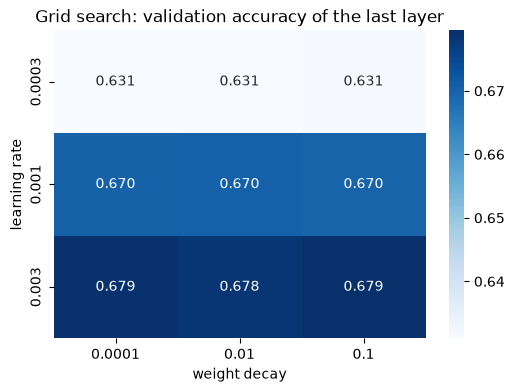

Best setting: {'learning rate': np.float64(0.003), 'weight decay': np.float64(0.1), 'Val Accuracy': np.float64(0.6795)}


In [43]:
def train_head(F_tr, y_tr, lr, wd, epochs=15, bs=512):
    torch.manual_seed(SEED)
    head = nn.Linear(F_tr.shape[1], 101).to(device)
    opt = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=wd)
    Xt, yt = torch.tensor(F_tr, device=device), torch.tensor(y_tr, device=device)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * int(np.ceil(len(yt) / bs)))
    for _ in range(epochs):
        perm = torch.randperm(len(yt), device=device)
        for i in range(0, len(yt), bs):
            j = perm[i:i + bs]
            loss = F.cross_entropy(head(F.dropout(Xt[j], 0.2)), yt[j], label_smoothing=0.1)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return head

def head_probs(head, F_):
    with torch.no_grad():
        return head(torch.tensor(F_, device=device)).softmax(1).cpu().numpy()

grid = []
for lr in [3e-4, 1e-3, 3e-3]:
    for wd in [1e-4, 1e-2, 1e-1]:
        head = train_head(F_train, y_train_sorted, lr, wd)
        grid.append({'learning rate': lr, 'weight decay': wd, 'Val Accuracy': round((head_probs(head, F_val).argmax(1) == y_val).mean(), 4)})
grid = pd.DataFrame(grid)
plt.figure(figsize=(6, 4))
sns.heatmap(grid.pivot(index='learning rate', columns='weight decay', values='Val Accuracy'), annot=True, fmt='.3f', cmap='Blues')
plt.title('Grid search: validation accuracy of the last layer')
plt.show()
best = grid.sort_values('Val Accuracy', ascending=False).iloc[0]
print('Best setting:', dict(best))

In [44]:
name = 'MobileNetV3 (feature extractor)'
head = train_head(F_train, y_train_sorted, best['learning rate'], best['weight decay'])
t0 = time.time()
fe_probs = head_probs(head, F_test)
add_result(name, 'Transfer learning, frozen CNN + grid search on last layer', fe_probs)

,Model,Approach,Input size,Test Accuracy,Top-5 Accuracy,Macro F1,Images / second (test)
0,MobileNetV3 (feature extractor),"Transfer learning, frozen CNN + grid search on...",224,0.6793,0.8879,0.6782,None


**Grid search result (validation accuracy):**

| learning rate \ weight decay | 0.0001 | 0.01 | 0.1 |
|---|---|---|---|
| 0.0003 | 0.631 | 0.631 | 0.631 |
| 0.001 | 0.670 | 0.670 | 0.670 |
| **0.003** | 0.679 | 0.679 | **0.680** |

- The **learning rate matters** (63.1% -> 67.9%): with only 15 epochs a small learning rate learns too slowly. **Weight decay makes almost no difference** (under 0.1 point), because a single linear layer on 70,690 photos is too simple to overfit.
- **Feature extractor result: 67.9% test accuracy, 88.8% top-5.** Better than our custom CNN (61.3%), even though the CNN was **never trained on food**: what it learned from ImageNet (edges, textures, objects) is useful for food too. It is also very cheap: 2 minutes to compute the features and a few seconds to train the last layer.
- But the frozen features were made for ImageNet's 1,000 objects (dogs, cars, ...), not for telling a steak from a filet mignon. The next step is to **fine-tune** the whole network.

### Model 3: MobileNetV3-Large fine-tuned
Now **all layers** of the pretrained MobileNetV3 are trained on the food photos, with a new output layer for 101 classes.

In [45]:
name = 'MobileNetV3 (fine-tuned)'
m = torchvision.models.mobilenet_v3_large(weights=torchvision.models.MobileNet_V3_Large_Weights.IMAGENET1K_V2)
m.classifier[3] = nn.Linear(1280, 101)
mobilenet, mobilenet_hist = train_model(name, m, EPOCHS[name], lr=1e-3)
mobilenet_probs = predict_probs(mobilenet, test_idx, name=name)
add_result(name, 'Transfer learning, fine-tuned', mobilenet_probs, mobilenet_hist, mobilenet)

MobileNetV3 (fine-tuned) | epoch 1/3 | train loss 2.518 | train acc 0.513 | val loss 1.416 | val acc 0.648 | 6.1 min


MobileNetV3 (fine-tuned) | epoch 2/3 | train loss 1.722 | train acc 0.727 | val loss 0.967 | val acc 0.765 | 5.5 min


MobileNetV3 (fine-tuned) | epoch 3/3 | train loss 1.400 | train acc 0.826 | val loss 0.790 | val acc 0.811 | 5.3 min


,Model,Approach,Input size,Test Accuracy,Top-5 Accuracy,Macro F1,Parameters (M),Epochs,Train minutes,Val Accuracy,Images / second (test)
0,MobileNetV3 (fine-tuned),"Transfer learning, fine-tuned",224,0.8077,0.9464,0.8074,4.33,3,17.0,0.8114,909


### Model 4: EfficientNet-B0 fine-tuned

In [46]:
name = 'EfficientNet-B0 (fine-tuned)'
m = torchvision.models.efficientnet_b0(weights=torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1)
m.classifier[1] = nn.Linear(1280, 101)
effnet, effnet_hist = train_model(name, m, EPOCHS[name], lr=1e-3)
effnet_probs = predict_probs(effnet, test_idx, name=name)
add_result(name, 'Transfer learning, fine-tuned', effnet_probs, effnet_hist, effnet)

EfficientNet-B0 (fine-tuned) | epoch 1/4 | train loss 2.673 | train acc 0.479 | val loss 1.286 | val acc 0.685 | 8.3 min


EfficientNet-B0 (fine-tuned) | epoch 2/4 | train loss 1.819 | train acc 0.698 | val loss 0.983 | val acc 0.756 | 8.6 min


EfficientNet-B0 (fine-tuned) | epoch 3/4 | train loss 1.526 | train acc 0.785 | val loss 0.769 | val acc 0.816 | 9.2 min


EfficientNet-B0 (fine-tuned) | epoch 4/4 | train loss 1.330 | train acc 0.848 | val loss 0.703 | val acc 0.832 | 8.7 min


,Model,Approach,Input size,Test Accuracy,Top-5 Accuracy,Macro F1,Parameters (M),Epochs,Train minutes,Val Accuracy,Images / second (test)
0,EfficientNet-B0 (fine-tuned),"Transfer learning, fine-tuned",224,0.821,0.9512,0.8205,4.14,4,34.9,0.8316,507


### Learning curves

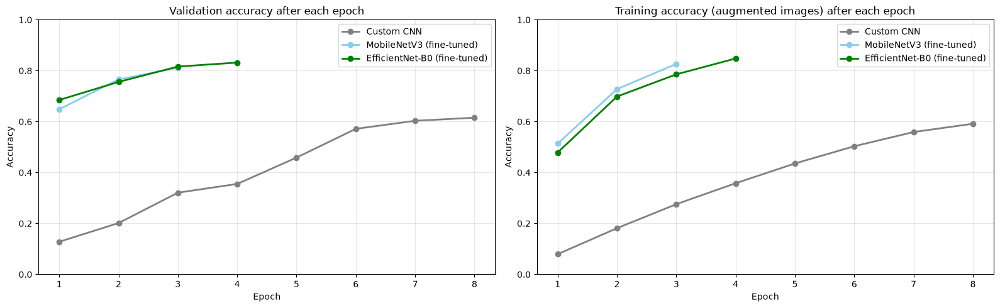

In [47]:
histories = {'Custom CNN': cnn_hist, 'MobileNetV3 (fine-tuned)': mobilenet_hist,
             'EfficientNet-B0 (fine-tuned)': effnet_hist}
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for (name, h), colour in zip(histories.items(), ['gray', 'skyblue', 'green']):
    axes[0].plot(h['Epoch'], h['Val Acc'], marker='o', linewidth=2, color=colour, label=name)
    axes[1].plot(h['Epoch'], h['Train Acc'], marker='o', linewidth=2, color=colour, label=name)
axes[0].set_title('Validation accuracy after each epoch'); axes[1].set_title('Training accuracy (augmented images) after each epoch')
for ax in axes:
    ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy'); ax.set_ylim(0, 1); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

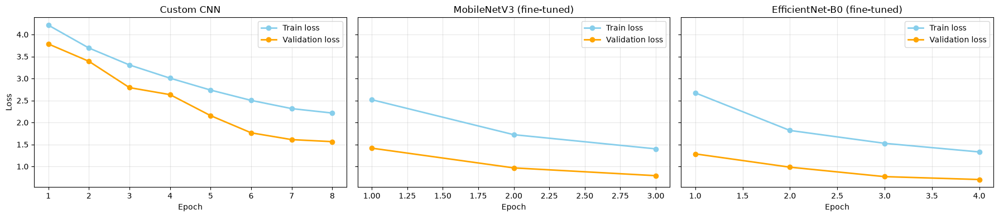

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h['Epoch'], h['Train Loss'], marker='o', color='skyblue', linewidth=2, label='Train loss')
    ax.plot(h['Epoch'], h['Val Loss'], marker='o', color='orange', linewidth=2, label='Validation loss')
    ax.set_title(name); ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylabel('Loss')
plt.tight_layout()
plt.show()

- **Fine-tuning learns much faster than training from scratch.** After only **one epoch** MobileNetV3 is at 64.8% and EfficientNet-B0 at 68.5% validation accuracy, already above the custom CNN after 8 epochs (61.5%).
- **EfficientNet-B0:** 68.5% -> 75.6% -> 81.6% -> **83.2%**. **MobileNetV3:** 64.8% -> 76.5% -> **81.1%**.
- **No overfitting:** training accuracy on augmented photos (84.8% for EfficientNet-B0) is close to the validation accuracy (83.2%), and the validation loss goes down every epoch for every model. The augmentation and label smoothing kept the models honest.
- **All curves were still going up at the last epoch**, so more epochs would give more accuracy (published results for EfficientNet-B0 on this dataset with longer training are around 85-88%). We used fewer epochs to keep the total run to about 1 hour.

### Comparing the 4 models on the test set

In [49]:
comparison = pd.DataFrame(results).set_index('Model')
comparison

,Approach,Input size,Test Accuracy,Top-5 Accuracy,Macro F1,Parameters (M),Epochs,Train minutes,Val Accuracy,Images / second (test)
Model,,,,,,,,,,
Custom CNN,Trained from scratch,128,0.6131,0.8451,0.6098,3.43,8.0,20.5,0.6152,1356.0
MobileNetV3 (feature extractor),"Transfer learning, frozen CNN + grid search on...",224,0.6793,0.8879,0.6782,NaN,NaN,NaN,NaN,NaN
MobileNetV3 (fine-tuned),"Transfer learning, fine-tuned",224,0.8077,0.9464,0.8074,4.33,3.0,17.0,0.8114,909.0
EfficientNet-B0 (fine-tuned),"Transfer learning, fine-tuned",224,0.8210,0.9512,0.8205,4.14,4.0,34.9,0.8316,507.0


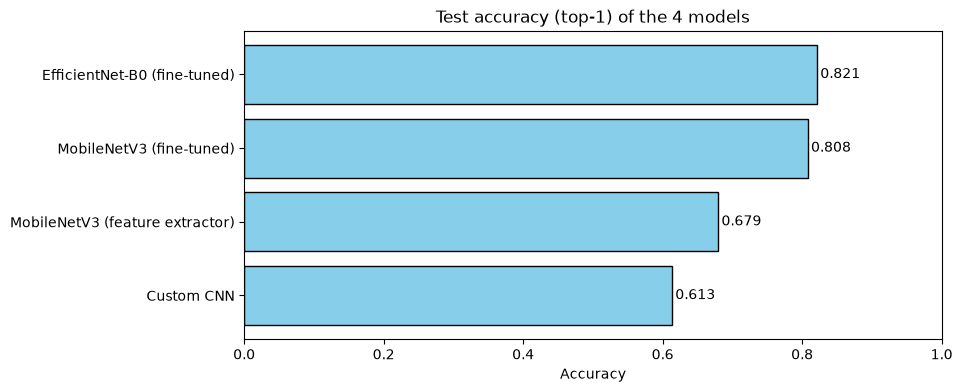

In [50]:
comp = comparison.sort_values('Test Accuracy')
plt.figure(figsize=(9, 4))
plt.barh(comp.index, comp['Test Accuracy'], color='skyblue', edgecolor='black')
for i, v in enumerate(comp['Test Accuracy']):
    plt.text(v + 0.005, i, f'{v:.3f}', va='center')
plt.xlim(0, 1)
plt.title('Test accuracy (top-1) of the 4 models')
plt.xlabel('Accuracy')
plt.show()

- **EfficientNet-B0 fine-tuned is the best single model: 82.1% accuracy, 95.1% top-5, macro F1 0.821**, followed closely by **MobileNetV3 fine-tuned: 80.8%** (94.6% top-5).
- Fine-tuning adds **+12.8 points** over the frozen MobileNetV3 (67.9% -> 80.8%) and **+20.8 points** over the custom CNN.
- **Accuracy vs speed:** MobileNetV3 trained in 17.0 min and predicts **909 images/second**; EfficientNet-B0 needed 34.9 min and predicts 507 images/second. Both have about the same number of parameters (4.3M and 4.1M, much smaller than the 25M of ResNet50), so both could run on a phone.
- **Macro F1 is almost equal to accuracy** for every model, because the classes are balanced.

## Ensembles and Test-Time Augmentation
- **Test-time augmentation (TTA):** each test photo is predicted twice, as it is and flipped left-right, and the two answers are averaged. A flipped pizza is still a pizza, so this gives a second opinion for free.
- **Soft Voting:** average the probabilities of the two fine-tuned CNNs (MobileNetV3 and EfficientNet-B0). Different networks make different mistakes, so the average is often better than each one.
- **Stacking:** a Logistic Regression learns how much to trust each CNN for each class. It is trained on the **validation** set predictions (images the CNNs never trained on) and tested on the test set.

In [51]:
tta = {}
for name, model in [('MobileNetV3 (fine-tuned)', mobilenet), ('EfficientNet-B0 (fine-tuned)', effnet)]:
    tta[name] = {'test': predict_probs(model, test_idx, tta=True, name=name + ' + TTA'),
                 'val': predict_probs(model, val_idx, tta=True)}
    add_result(name + ' + TTA', 'Fine-tuned + flip TTA', tta[name]['test'], model=model)

vote_probs = np.mean([t['test'] for t in tta.values()], axis=0)
add_result('Soft Voting (2 CNNs + TTA)', 'Ensemble: average of probabilities', vote_probs)

,Model,Approach,Input size,Test Accuracy,Top-5 Accuracy,Macro F1,Images / second (test)
0,Soft Voting (2 CNNs + TTA),Ensemble: average of probabilities,224,0.8348,0.9558,0.8345,None


In [52]:
from sklearn.linear_model import LogisticRegression

stack_val = np.hstack([np.log(t['val'] + 1e-6) for t in tta.values()])
stack_test = np.hstack([np.log(t['test'] + 1e-6) for t in tta.values()])
stacker = LogisticRegression(C=0.05, max_iter=2000)
stacker.fit(stack_val, y_val)
stack_probs = stacker.predict_proba(stack_test)
add_result('Stacking (2 CNNs + TTA)', 'Ensemble: logistic regression on CNN outputs', stack_probs)

,Model,Approach,Input size,Test Accuracy,Top-5 Accuracy,Macro F1,Images / second (test)
0,Stacking (2 CNNs + TTA),Ensemble: logistic regression on CNN outputs,224,0.8072,0.9438,0.8074,None


In [53]:
final_table = pd.DataFrame(results).set_index('Model')
final_table[['Approach', 'Test Accuracy', 'Top-5 Accuracy', 'Macro F1', 'Parameters (M)', 'Train minutes', 'Images / second (test)']]

,Approach,Test Accuracy,Top-5 Accuracy,Macro F1,Parameters (M),Train minutes,Images / second (test)
Model,,,,,,,
Custom CNN,Trained from scratch,0.6131,0.8451,0.6098,3.43,20.5,1356.0
MobileNetV3 (feature extractor),"Transfer learning, frozen CNN + grid search on...",0.6793,0.8879,0.6782,NaN,NaN,NaN
MobileNetV3 (fine-tuned),"Transfer learning, fine-tuned",0.8077,0.9464,0.8074,4.33,17.0,909.0
EfficientNet-B0 (fine-tuned),"Transfer learning, fine-tuned",0.8210,0.9512,0.8205,4.14,34.9,507.0
MobileNetV3 (fine-tuned) + TTA,Fine-tuned + flip TTA,0.8095,0.9476,0.8092,4.33,NaN,463.0
EfficientNet-B0 (fine-tuned) + TTA,Fine-tuned + flip TTA,0.8254,0.9524,0.8250,4.14,NaN,271.0
Soft Voting (2 CNNs + TTA),Ensemble: average of probabilities,0.8348,0.9558,0.8345,NaN,NaN,NaN
Stacking (2 CNNs + TTA),Ensemble: logistic regression on CNN outputs,0.8072,0.9438,0.8074,NaN,NaN,NaN


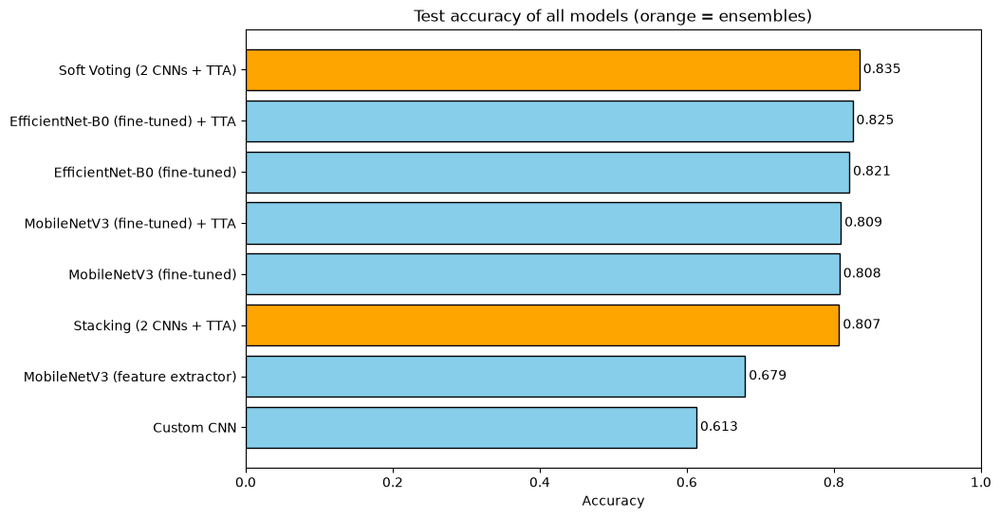

In [54]:
ft = final_table.sort_values('Test Accuracy')
plt.figure(figsize=(10, 6))
colours = ['orange' if ('Voting' in n or 'Stacking' in n) else 'skyblue' for n in ft.index]
plt.barh(ft.index, ft['Test Accuracy'], color=colours, edgecolor='black')
for i, v in enumerate(ft['Test Accuracy']):
    plt.text(v + 0.005, i, f'{v:.3f}', va='center')
plt.xlim(0, 1)
plt.title('Test accuracy of all models (orange = ensembles)')
plt.xlabel('Accuracy')
plt.show()

- **Test-time augmentation (flip) helps a little for free:** EfficientNet-B0 82.1% -> **82.5%**, MobileNetV3 80.8% -> **81.0%**. The cost is two predictions per photo (EfficientNet-B0: 507 -> 271 images/second, still fast).
- **Soft Voting is the best model overall: 83.5% accuracy, 95.6% top-5, macro F1 0.834**, +0.9 points over EfficientNet-B0 + TTA. The two networks make partly different mistakes, so averaging them corrects some errors.
- **Stacking did worse (80.7%)**, below both of its CNNs. The logistic regression had to learn 202 inputs x 101 classes from only **5,052 validation photos** (50 per class), which is too little, so it overfits. Simple averaging needs no training and is the safer way to combine models here.

## Chosen Model
We choose **EfficientNet-B0 (fine-tuned) + flip TTA** as the final model:
- Best **single** model: **82.5% accuracy, 95.2% top-5**.
- The Soft Voting ensemble is 0.9 points better (83.5%), but it needs **two networks** for every photo (about double the computing time and memory). For a food app that runs on a phone, one small model (4.1 million parameters, 16 MB file) is the better trade-off. If the app runs on a server, the ensemble is a good upgrade.

In [55]:
from sklearn.metrics import classification_report, confusion_matrix

FINAL_NAME = 'EfficientNet-B0 (fine-tuned) + TTA'
final_model = effnet
final_probs = tta['EfficientNet-B0 (fine-tuned)']['test']
final_pred = final_probs.argmax(1)
print(FINAL_NAME, {k: round(v, 4) for k, v in scores(y_test, final_probs).items()})
report = pd.DataFrame(classification_report(y_test, final_pred, target_names=class_names, output_dict=True)).T
report.loc[['accuracy', 'macro avg', 'weighted avg']]

EfficientNet-B0 (fine-tuned) + TTA {'Test Accuracy': 0.8254, 'Top-5 Accuracy': 0.9524, 'Macro F1': 0.825}


,precision,recall,f1-score,support
accuracy,0.825372,0.825372,0.825372,0.825372
macro avg,0.826295,0.825377,0.825044,25248.000000
weighted avg,0.826290,0.825372,0.825039,25248.000000


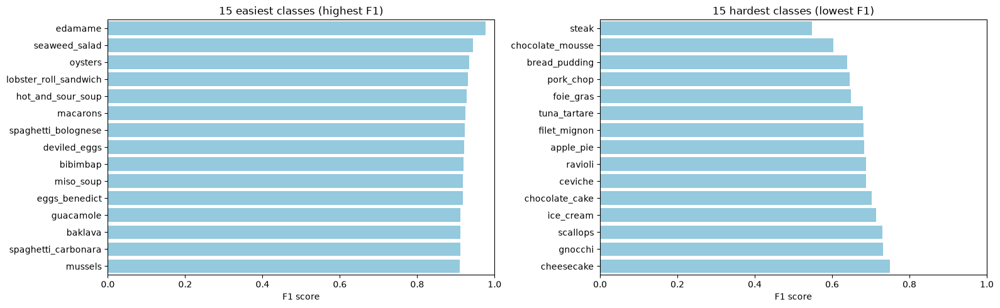

In [56]:
per_class = report.iloc[:101].sort_values('f1-score')
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=per_class['f1-score'].tail(15)[::-1], y=per_class.tail(15).index[::-1], color='skyblue', ax=axes[0])
sns.barplot(x=per_class['f1-score'].head(15), y=per_class.head(15).index, color='skyblue', ax=axes[1])
axes[0].set_title('15 easiest classes (highest F1)'); axes[1].set_title('15 hardest classes (lowest F1)')
for ax in axes: ax.set_xlim(0, 1); ax.set_xlabel('F1 score'); ax.set_ylabel('')
plt.tight_layout()
plt.show()

In [57]:
cm = confusion_matrix(y_test, final_pred, labels=range(101))
pairs = []
for t in range(101):
    for p in range(101):
        if t != p and cm[t, p] > 0:
            pairs.append([class_names[t], class_names[p], cm[t, p], round(cm[t, p] / cm[t].sum() * 100, 1)])
pairs = pd.DataFrame(pairs, columns=['True class', 'Predicted as', 'Images', '% of the true class']).sort_values('Images', ascending=False)
pairs.head(15)

,True class,Predicted as,Images,% of the true class
1949,steak,filet_mignon,38,15.2
520,chocolate_mousse,chocolate_cake,35,14.0
824,filet_mignon,steak,34,13.6
506,chocolate_cake,chocolate_mousse,26,10.4
667,donuts,beignets,25,10.0
2,apple_pie,bread_pudding,22,8.8
1956,steak,pork_chop,21,8.4
2087,tuna_tartare,beef_tartare,20,8.0
1958,steak,prime_rib,19,7.6
102,beef_tartare,tuna_tartare,19,7.6


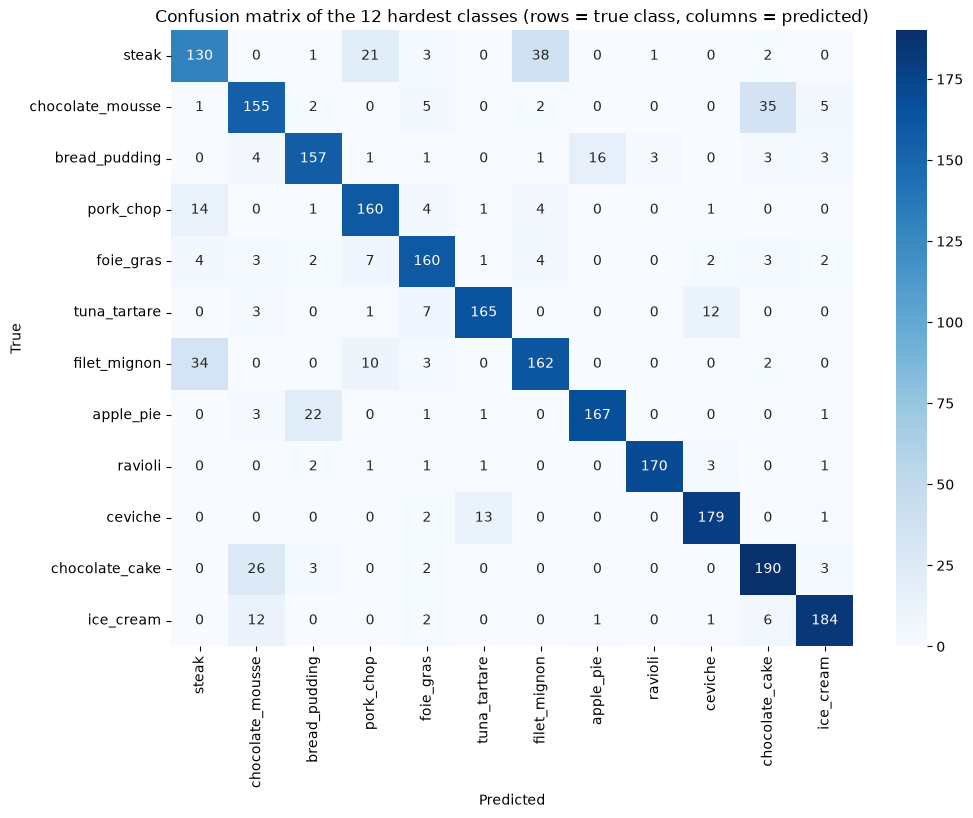

In [58]:
# confusion matrix for the 12 hardest classes
hard = [class_names.index(c) for c in per_class.head(12).index]
plt.figure(figsize=(11, 8))
sns.heatmap(pd.DataFrame(cm[np.ix_(hard, hard)], index=[class_names[i] for i in hard], columns=[class_names[i] for i in hard]),
            annot=True, fmt='d', cmap='Blues')
plt.title('Confusion matrix of the 12 hardest classes (rows = true class, columns = predicted)')
plt.ylabel('True'); plt.xlabel('Predicted')
plt.show()

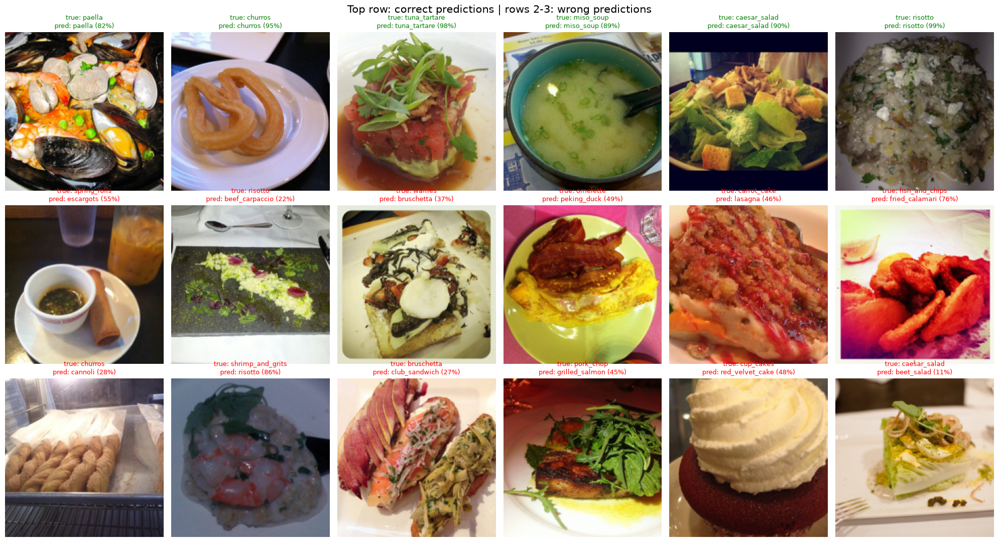

In [59]:
# examples of correct and wrong predictions
right = np.where(final_pred == y_test)[0]; wrong = np.where(final_pred != y_test)[0]
pick = list(rng.choice(right, 6, replace=False)) + list(rng.choice(wrong, 12, replace=False))
fig, axes = plt.subplots(3, 6, figsize=(20, 11))
for ax, k in zip(axes.ravel(), pick):
    ax.imshow(X[test_idx[k]]); ax.axis('off')
    ok = final_pred[k] == y_test[k]
    ax.set_title(f'true: {class_names[y_test[k]]}\npred: {class_names[final_pred[k]]} ({final_probs[k].max():.0%})',
                 fontsize=9, color='green' if ok else 'red')
plt.suptitle('Top row: correct predictions | rows 2-3: wrong predictions', fontsize=15)
plt.tight_layout()
plt.show()

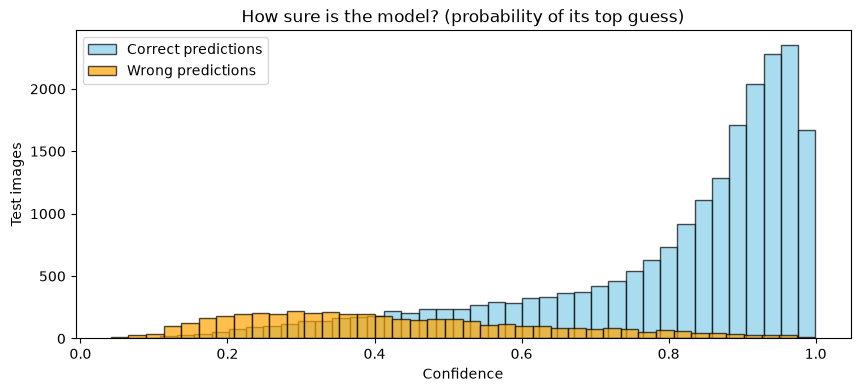

In [60]:
conf = final_probs.max(1)
plt.figure(figsize=(10, 4))
plt.hist(conf[final_pred == y_test], bins=40, alpha=0.7, color='skyblue', edgecolor='black', label='Correct predictions')
plt.hist(conf[final_pred != y_test], bins=40, alpha=0.7, color='orange', edgecolor='black', label='Wrong predictions')
plt.title('How sure is the model? (probability of its top guess)')
plt.xlabel('Confidence'); plt.ylabel('Test images'); plt.legend()
plt.show()

**Result**
- On the **25,248 test photos**, the model is right **82.5%** of the time, and the correct food is in its **top 5 guesses 95.2%** of the time. Precision (82.6%) and recall (82.5%) are balanced.
- **15 classes have F1 of 0.90 or more**: **edamame (0.976), seaweed salad (0.944), oysters (0.935), lobster roll sandwich (0.930), hot and sour soup (0.929), macarons (0.925)**. These foods have a unique colour or shape.
- **10 classes have F1 below 0.70**: **steak (0.549), chocolate mousse (0.603), bread pudding (0.638), pork chop (0.645), foie gras (0.649), tuna tartare, filet mignon, apple pie**.
- **The mistakes make sense:** the most confused pairs are dishes that even people mix up: **steak -> filet mignon (15.2% of steak photos)** and back (13.6%), **chocolate mousse -> chocolate cake (14.0%)**, **donuts -> beignets (10.0%)**, apple pie <-> bread pudding, tuna tartare <-> beef tartare, ravioli -> gnocchi, dumplings -> gyoza, sushi -> sashimi. Steak is mixed up with 3 other meats (filet mignon, pork chop, prime rib).
- Some "wrong" predictions are really **unclear photos**: a spring roll next to a bowl of sauce, a cupcake with a dark red base predicted as red velvet cake, a seafood risotto-like dish labelled shrimp and grits.
- **Confidence:** correct predictions are usually very confident (most above 0.8), while wrong ones are spread at low confidence. So the model's confidence can be trusted, which we use in Part 3.

### Using the model on a new photo
`predict_food()` takes the path of any food photo and returns the **5 most likely foods** with their probabilities.

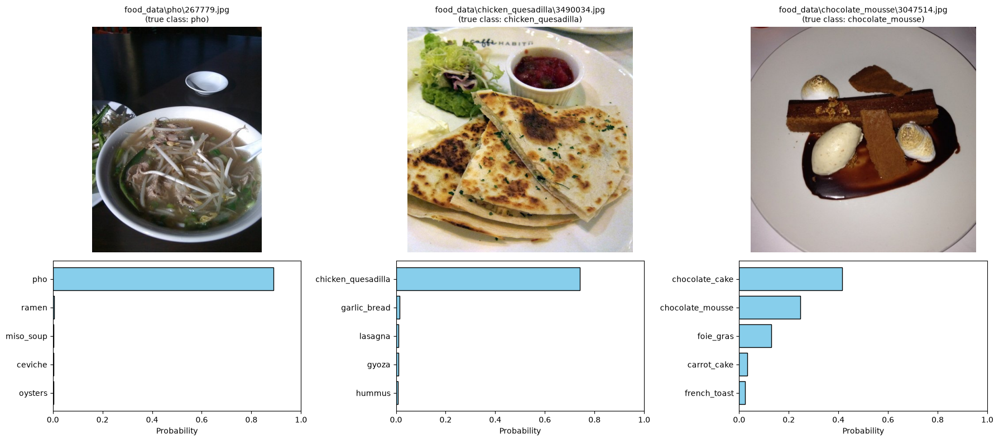

In [61]:
def predict_food(path, model=final_model, top=5):
    img = load_and_resize(path)
    m = (CACHE_SIZE - IMG_SIZE) // 2
    xb = torch.from_numpy(np.ascontiguousarray(img[m:m + IMG_SIZE, m:m + IMG_SIZE]))[None]
    model.eval()
    with torch.no_grad(), torch.autocast(device_type=device, dtype=torch.bfloat16):
        x = to_input(xb)
        p = ((model(x).float().softmax(1) + model(x.flip(3)).float().softmax(1)) / 2)[0].cpu().numpy()
    best = p.argsort()[::-1][:top]
    return pd.DataFrame({'Food': [class_names[i] for i in best], 'Probability': p[best].round(3)})

fig, axes = plt.subplots(2, 3, figsize=(18, 8), gridspec_kw={'height_ratios': [3, 2]})
for c, k in enumerate(rng.choice(len(test_idx), 3, replace=False)):
    path = df['Path'].iat[test_idx[k]]
    res = predict_food(path)
    axes[0, c].imshow(Image.open(path)); axes[0, c].axis('off')
    axes[0, c].set_title(f'{path}\n(true class: {df["Class"].iat[test_idx[k]]})', fontsize=10)
    axes[1, c].barh(res['Food'][::-1], res['Probability'][::-1], color='skyblue', edgecolor='black')
    axes[1, c].set_xlim(0, 1); axes[1, c].set_xlabel('Probability')
plt.tight_layout()
plt.show()

In [62]:
torch.save({'model_state': final_model.state_dict(), 'architecture': 'efficientnet_b0', 'classes': class_names,
            'image_size': IMG_SIZE, 'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225]},
           os.path.join(MODEL_DIR, 'final_food_classifier.pt'))
print('Saved', os.path.join(MODEL_DIR, 'final_food_classifier.pt'))

Saved food_models\final_food_classifier.pt


# Part 3: Suggestions for Using the Model in a Food App
## 1. Can the app know when it is unsure?

In [63]:
rows = []
for t in [0, 0.3, 0.5, 0.7, 0.8, 0.9]:
    keep = conf >= t
    rows.append([t, round(keep.mean() * 100, 1), round((final_pred[keep] == y_test[keep]).mean() * 100, 1),
                 round(np.mean([y_test[i] in final_probs[i].argsort()[-3:] for i in np.where(~keep)[0]]) * 100, 1) if (~keep).any() else None])
pd.DataFrame(rows, columns=['Confidence at least', '% of photos answered directly', 'Accuracy on those %',
                            'Other photos: true food in top-3 %'])

,Confidence at least,% of photos answered directly,Accuracy on those %,Other photos: true food in top-3 %
0,0.0,100.0,82.5,NaN
1,0.3,92.3,87.1,58.0
2,0.5,79.9,92.7,73.0
3,0.7,65.9,96.4,81.1
4,0.8,55.6,97.9,84.6
5,0.9,35.0,98.9,89.1


## 2. Which foods get mixed up? (groups of similar dishes)

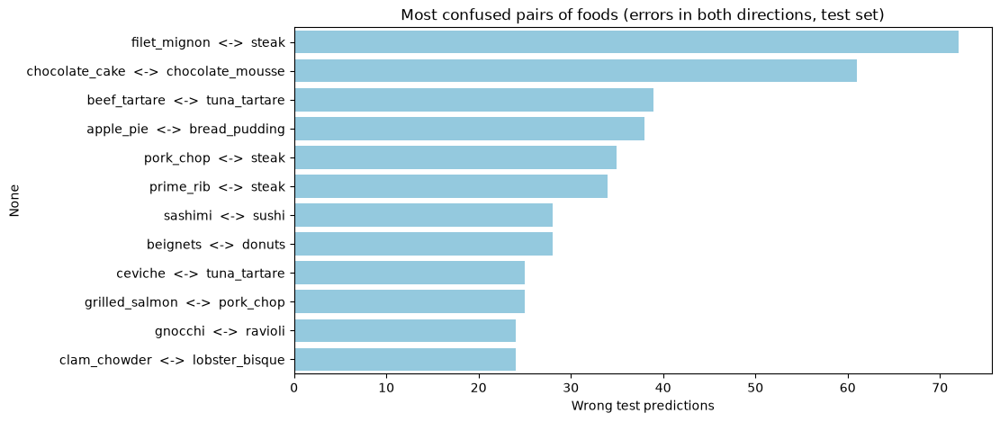

Errors on the 12 most confused pairs: 433 of 4409 total errors


In [64]:
# confusion in both directions for each pair of classes
both = {}
for _, r in pairs.iterrows():
    key = tuple(sorted([r['True class'], r['Predicted as']]))
    both[key] = both.get(key, 0) + r['Images']
both = pd.Series(both).sort_values(ascending=False).head(12)
both.index = [f'{a}  <->  {b}' for a, b in both.index]
plt.figure(figsize=(10, 5))
sns.barplot(x=both.values, y=both.index, color='skyblue')
plt.title('Most confused pairs of foods (errors in both directions, test set)')
plt.xlabel('Wrong test predictions')
plt.show()
print('Errors on the 12 most confused pairs:', both.sum(), 'of', (final_pred != y_test).sum(), 'total errors')

## 3. Fair comparison: Do dark or cropped photos hurt the model?
Some foods are naturally darker (chocolate cake, steak) and some classes are just harder, so comparing "dark photos" against "all photos" would mix the effect of the **food** with the effect of the **light**. To be fair, each photo is compared **only with photos of the same food**:
- a photo is "dark" if it is in the darkest 20% **of its own class**, "low contrast" if it is in the lowest 20% of contrast **of its own class**;
- a photo is "cropped" if it is far from square (short side < 80% of the long side), so the centre crop cuts off part of the plate;
- the accuracy of these photos is compared with the other photos of the same class, and the difference is averaged over the 101 classes.

In [65]:
test_df = df.loc[test_idx, ['Class', 'BRIGHTNESS', 'CONTRAST', 'Width', 'Height']].copy()
test_df['CORRECT'] = (final_pred == y_test).astype(int)
test_df['DARK'] = test_df.groupby('Class')['BRIGHTNESS'].transform(lambda s: s <= s.quantile(0.2)).astype(bool)
test_df['BRIGHT'] = test_df.groupby('Class')['BRIGHTNESS'].transform(lambda s: s >= s.quantile(0.8)).astype(bool)
test_df['LOW CONTRAST'] = test_df.groupby('Class')['CONTRAST'].transform(lambda s: s <= s.quantile(0.2)).astype(bool)
test_df['CROPPED'] = test_df[['Width', 'Height']].min(axis=1) / test_df[['Width', 'Height']].max(axis=1) < 0.8   # centre crop cuts off > 20%

fair = []
for flag in ['DARK', 'BRIGHT', 'LOW CONTRAST', 'CROPPED']:
    g = test_df.groupby(['Class', flag])['CORRECT'].mean().unstack().reindex(columns=[False, True])
    g = g.dropna()   # keep classes that have photos in both groups
    diff = (g[True] - g[False]) * 100
    fair.append([flag, int(test_df[flag].sum()), round(test_df.loc[test_df[flag], 'CORRECT'].mean() * 100, 1),
                 round(test_df.loc[~test_df[flag], 'CORRECT'].mean() * 100, 1), round(diff.mean(), 1), len(g),
                 int((diff < 0).sum())])
pd.DataFrame(fair, columns=['Photo group', 'Test photos', 'Accuracy in group %', 'Accuracy of the rest %',
                            'Within-class difference (points)', 'Classes compared', 'Classes where the group is worse'])

,Photo group,Test photos,Accuracy in group %,Accuracy of the rest %,Within-class difference (points),Classes compared,Classes where the group is worse
0,DARK,5068,78.5,83.5,-5.0,101,74
1,BRIGHT,5058,83.9,82.2,1.7,101,35
2,LOW CONTRAST,5077,81.4,82.8,-1.4,101,59
3,CROPPED,9147,81.6,83.1,-1.6,101,63


## 4. Which classes need more or better photos?

In [66]:
per_class_acc = test_df.groupby('Class')['CORRECT'].mean().mul(100).sort_values()
worst = per_class_acc.head(10).round(1).to_frame('Test accuracy %')
worst['Most often predicted as'] = [pairs[pairs['True class'] == c]['Predicted as'].iloc[0] for c in worst.index]
worst

,Test accuracy %,Most often predicted as
Class,,
steak,52.0,filet_mignon
chocolate_mousse,62.0,chocolate_cake
bread_pudding,62.8,apple_pie
foie_gras,64.0,scallops
pork_chop,64.0,baby_back_ribs
filet_mignon,64.8,steak
tuna_tartare,66.0,beef_tartare
apple_pie,66.8,bread_pudding
ravioli,68.0,gnocchi


## Suggestions for the Food App Team

**A note on fair comparison:** some classes are darker or harder than others by nature (chocolate desserts, steak), so the effect of photo quality was checked **inside each class**: dark photos were compared only with photos of the same food, and the differences were averaged over the 101 classes.

**1. Use the confidence to decide how to answer (the most useful rule).**
- If the model's confidence is **at least 0.7**, show the answer directly: this covers **65.9% of the photos** and they are right **96.4%** of the time.
- At **0.5 or more**: 79.9% of the photos, 92.7% right. At **0.9 or more**: 35.0% of the photos, 98.9% right.
- When the confidence is **below 0.7**, show the **top-3 foods** and let the user tap the right one: the true food is in the top 3 for **81.1%** of these photos. This turns an 82.5% model into an app that is almost always helpful.

**2. Handle similar dishes as groups.** The 12 most confused pairs (steak / filet mignon, chocolate mousse / chocolate cake, donuts / beignets, apple pie / bread pudding, tuna / beef tartare, ...) cause **433 of the 4,409 test errors (9.8%)**. For uses like calorie counting, steak vs filet mignon or tuna vs beef tartare matters little, so the app can show a **food group** ("beef steak", "chocolate dessert", "tartare") when the top two guesses are in the same group, and ask only when it matters.

**3. Ask the user for better light.** Fair comparison: **dark photos are 5.0 points less accurate than other photos of the same food**, and worse in **74 of the 101 classes** (78.5% vs 83.5%). Low-contrast photos lose 1.4 points and very non-square photos (where the centre crop cuts part of the plate) lose 1.6 points. Bright photos are not a problem (+1.7). The app should **warn when a photo is very dark** (brightness below about 46, the lower IQR limit) and suggest using the flash, and should let the user **frame the plate in a square**.

**4. Collect more and cleaner photos for the weakest classes.** **Steak (52.0% test accuracy), chocolate mousse (62.0%), bread pudding (62.8%), foie gras (64.0%), pork chop (64.0%), filet mignon (64.8%), tuna tartare (66.0%), apple pie (66.8%)** need more examples, especially photos where the difference to their look-alike is visible (cut steak, mousse in a glass). Users' corrections from point 1 can be saved to become new labelled training photos.

**5. Clean the labels.** The dataset contains black photos, menus, collages and the same photo under two different classes. A simple check is to have a person review training photos where the model strongly disagrees with the label.

**6. Next steps for the model.** All learning curves were still rising, so **training longer** (10-15 epochs), using a **larger input size** or a bigger network (EfficientNet-B2/B3), and using the **Soft Voting ensemble** on a server (83.5%) are the most direct ways to gain more accuracy.

# Model Comparison Report
**Goal:** Classify a food photo into one of **101 food types**. The data has 101,000 photos (1,000 per class); after removing 10 duplicates, 100,990 photos were split per class into **70% training (70,690), 5% validation (5,052) and 25% test (25,248)**. All results below are on the **test set**, which was never used for training or for choosing settings.

| Model | Approach | Test Accuracy | Top-5 Accuracy | Macro F1 | Train time | Speed (images/s) |
|---|---|---|---|---|---|---|
| Random Forest (simple features) | Colour, size, contrast columns | 4.1% | 13.5% | 0.036 | < 1 min | - |
| Custom CNN (128 px) | CNN trained from scratch, 8 epochs | 61.3% | 84.5% | 0.610 | 20.5 min | 1,356 |
| MobileNetV3 (feature extractor) | Frozen pretrained CNN + grid-searched last layer | 67.9% | 88.8% | 0.678 | 2 min | - |
| MobileNetV3 (fine-tuned) | Transfer learning, 3 epochs | 80.8% | 94.6% | 0.807 | 17.0 min | 909 |
| MobileNetV3 + TTA | + flipped image | 81.0% | 94.8% | 0.809 | - | 463 |
| EfficientNet-B0 (fine-tuned) | Transfer learning, 4 epochs | 82.1% | 95.1% | 0.821 | 34.9 min | 507 |
| **EfficientNet-B0 + TTA (chosen)** | + flipped image | **82.5%** | **95.2%** | **0.825** | - | 271 |
| Soft Voting (2 CNNs + TTA) | Average of probabilities | 83.5% | 95.6% | 0.834 | - | - |
| Stacking (2 CNNs + TTA) | Logistic regression on CNN outputs | 80.7% | 94.4% | 0.807 | - | - |

**Conclusions**
- **Pixels beat hand-made features:** a Random Forest on colour and size features gets 4.1%; a small CNN learning from the pixels gets 61.3%.
- **Transfer learning is the key technique:** a CNN pretrained on ImageNet and fine-tuned on food reaches **80-83% in 3-4 epochs**, 20 points above the CNN trained from scratch, at a lower training time.
- **Fine-tuning beats freezing** by 12.8 points (80.8% vs 67.9%), because the network adapts its features to food details.
- **EfficientNet-B0 is the best single model** (82.5% with TTA), with MobileNetV3 close behind (81.0%) and almost twice as fast.
- **Soft Voting is the most accurate (83.5%)**, while stacking overfit on the small validation set.
- **Chosen model: EfficientNet-B0 + TTA**: high accuracy from one small model (4.1M parameters) that can run in a mobile app; saved as `food_models/final_food_classifier.pt` with the class names, and usable on any photo through `predict_food()`.
- With confidence above 0.7, the model is right **96.4%** of the time on two-thirds of the photos. Most remaining errors are between dishes that look alike (steak / filet mignon, chocolate mousse / cake).